# City Hospital - Data Preprocessing & Exploratory Analysis
**Final Group Project - Data Preprocessing and Visualization · DP Team**

Raw data: `Project_Data.xlsx` (one row per consultation, Jan-Jun 2024, 10,008 rows, 500 patients). Goal: clean the data, build a patient-level Analytic Base Table (`ABT_city_hospital.csv`) and explore it.

**How to run:** put this notebook in the same folder as `Project_Data.xlsx` and choose *Run all*. Requires `pandas`, `numpy`, `matplotlib`, `seaborn` and `openpyxl`. The Excel file is never modified: all cleaning is done in code.

**Outputs:** `ABT_city_hospital.csv`, `data_dictionary.csv`, `cleaning_log.csv`, `visit_level_clean.csv`.

---

<a id="toc"></a>

## Table of Contents

- [1. Part A - Data Understanding & Cleaning](#1)
  - [1.1 Loading and Importing the Data](#1_1)
    - [1.1.1 Initial Understanding of the Dataset](#1_1_1)
  - [1.2 Handling Duplicate Records](#1_2)
    - [1.2.1 Identifying Duplicate Rows](#1_2_1)
    - [1.2.2 Removing Duplicate Records](#1_2_2)
    - [1.2.3 Justifying the Cleaning Decisions](#1_2_3)
  - [1.3 Identifying and Handling Missing Values](#1_3)
    - [1.3.1 Identifying Missing Values Across Variables](#1_3_1)
    - [1.3.2 Analysing Missing Data Patterns](#1_3_2)
    - [1.3.3 Applying Imputation Strategies](#1_3_3)
  - [1.4 Handle Inconsistent Data](#1_4)
    - [1.4.1 Identifying Inconsistent Data (Negative Values, Incorrect Dates)](#1_4_1)
    - [1.4.2 Correcting Data Types for Optimal Performance](#1_4_2)
    - [1.4.3 Checking Demographic and Socio-Economic Variables](#1_4_3)
    - [1.4.4 Identifying Inconsistent Patient Attributes (Static Features)](#1_4_4)
    - [1.4.5 Correcting Inconsistencies Across Patient Visits](#1_4_5)
    - [1.4.6 Identifying Invalid Category Labels](#1_4_6)
    - [1.4.7 Correcting Satisfaction Level Values](#1_4_7)
    - [1.4.8 Checking Logical Contradictions](#1_4_8)
    - [1.4.9 Checking Invalid Insurance Coverages](#1_4_9)
  - [1.5 Identifying and Handling Outliers](#1_5)
    - [1.5.1 Detecting Outliers in Numerical Variables](#1_5_1)
    - [1.5.2 Visualizing Potential Outliers](#1_5_2)
    - [1.5.3 Deciding How to Handle Outliers](#1_5_3)

- [2. Part B - Feature Engineering & ABT Construction](#2)
  - [2.1 Patient-Level ABT Construction](#2_1)
    - [2.1.1 Static Attributes](#2_1_1)
    - [2.1.2 Visit Behaviour Features](#2_1_2)
    - [2.1.3 Financial Features](#2_1_3)
    - [2.1.4 Satisfaction Features](#2_1_4)
    - [2.1.5 Recency and Activity Features](#2_1_5)
  - [2.2 Data Dictionary](#2_2)
  - [2.3 Exporting the ABT](#2_3)

- [3. Part C - Exploratory Visualization & Insights](#3)
  - [3.1 Patient Demographics](#3_1)
    - [3.1.1 Age Distribution](#3_1_1)
    - [3.1.2 Gender Distribution](#3_1_2)
    - [3.1.3 Income Distribution](#3_1_3)
  - [3.2 Department and Service Usage](#3_2)
    - [3.2.1 Consultations by Department](#3_2_1)
    - [3.2.2 Consultations Over Time](#3_2_2)
    - [3.2.3 Department Usage by Gender or Age Group](#3_2_3)
  - [3.3 Patient Satisfaction](#3_3)
    - [3.3.1 Satisfaction by Department](#3_3_1)
    - [3.3.2 Satisfaction by Patient Segment](#3_3_2)
  - [3.4 Additional Visualizations](#3_4)
  - [3.5 Management Questions and Key Insights](#3_5)

<a id="1"></a>

# 1. Part A - Data Understanding & Cleaning

[Back to TOC](#toc)

Every issue is detected in code, a decision is taken (**correct / impute / flag / remove**) and logged in `LOG` (exported as `cleaning_log.csv`). Patients are never removed: every problem is repaired or flagged at visit level.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)

REF_DATE = pd.Timestamp("2024-07-01")              # reference date for recency features
AGE_BINS = [-1, 17, 34, 49, 64, 79, 200]
AGE_LAB = ["0-17", "18-34", "35-49", "50-64", "65-79", "80+"]
EDU = ["Kindergarten", "Pre-school", "Elementary school", "Middle school/junior high",
       "High school", "Undergraduate", "Master", "PhD"]   # ordered education levels

LOG = []      # cleaning log (issue -> decision -> justification)
STATS = {}    # numbers reused in the report


def log(issue, variable, n_rows, decision, why):
    LOG.append(dict(issue=issue, variable=variable, rows_affected=int(n_rows),
                    decision=decision, justification=why))

<a id="1_1"></a>

## 1.1 Loading and Importing the Data

[Back to TOC](#toc)

In [3]:
# Load. keep_default_na=False because the literal string "None" (= no insurance / no family history)
# would otherwise be silently converted to NaN by pandas.
data = pd.read_excel("Project_Data.xlsx", keep_default_na=False, na_values=[""])
STATS["raw_rows"], STATS["raw_cols"] = data.shape
STATS["raw_patients"] = int(data["Patient ID"].nunique())
STATS["raw_dtypes"] = {k: str(v) for k, v in data.dtypes.items()}
STATS["raw_missing"] = {k: int(v) for k, v in data.isna().sum().items() if v}

print(f"Dimensions      : {data.shape[0]:,} rows x {data.shape[1]} columns")
print(f"Unique patients : {STATS['raw_patients']}")
print("\nData types:")
print(data.dtypes.to_string())

# naive read, only to document the "None" trap
naive = pd.read_excel("Project_Data.xlsx")
STATS["naive_missing_insurance"] = int(naive["Insurance Provider"].isna().sum())
STATS["naive_missing_family"] = int(naive["Family History"].isna().sum())
n_true_ins = int(data["Insurance Provider"].isna().sum())
log("'None' category read as missing by default", "Insurance Provider, Family History",
    STATS["naive_missing_insurance"] + STATS["naive_missing_family"] - n_true_ins,
    "Keep 'None' as a valid category (read with keep_default_na=False)",
    "'None' means no insurance / no family history, not missing data; treating it as NaN would hide "
    f"{STATS['naive_missing_insurance'] - n_true_ins} uninsured rows and "
    f"{STATS['naive_missing_family']} rows without family history.")

df = data.copy()               # all cleaning happens on this copy
df["row_id"] = np.arange(len(df))

Dimensions      : 10,008 rows x 16 columns
Unique patients : 500

Data types:
Patient ID                            int64
Age                                 float64
Gender                                  str
City of Residence                       str
Profession                              str
Insurance Provider                      str
Family History                          str
Education Level                         str
Marital Status                          str
Visit Date                   datetime64[us]
Department                              str
Consultation Duration                 int64
Satisfaction Level                    int64
Approximate Annual Income           float64
Consultation Price                  float64
Insurance Coverage                  float64


<a id="1_1_1"></a>

### 1.1.1 Initial Understanding of the Dataset

In [4]:
display(data.head())

print("Visit dates      :", data["Visit Date"].min().date(), "->", data["Visit Date"].max().date())
rpp = data.groupby("Patient ID").size()
print("Visits / patient :", rpp.min(), "to", rpp.max(), f"(mean {rpp.mean():.1f})")

print("\nNumerical summary:")
display(data.describe().T.round(2))

print("\nNumber of distinct labels in the categorical variables:")
cat_raw = data.select_dtypes(exclude=["number", "datetime"]).columns
display(data[cat_raw].nunique().to_frame("n_labels").T)

,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
0,1482,65.0,Female,Birmingham,Retired,None,Heart Disease,Master,Divorced,2024-02-22,Endocrinology,110,2,38839.0,293.014042,0.0
1,1482,65.0,Female,Birmingham,Retired,None,Heart Disease,Master,Divorced,2024-01-21,Emergency,76,4,52219.0,287.208982,0.0
2,1482,65.0,Female,Birmingham,Retired,None,Heart Disease,Master,Divorced,2024-06-13,Neurology,17,5,41491.0,241.254507,0.0
3,1482,65.0,Female,Birmingham,Retired,None,Heart Disease,Master,Divorced,2024-03-24,Emergency,15,3,34944.0,221.177483,0.0
4,1482,65.0,Female,Birmingham,Retired,None,Heart Disease,Master,Divorced,2024-03-19,Neurology,99,1,39248.0,219.743794,0.0


Visit dates      : 2024-01-01 -> 2024-06-30
Visits / patient : 9 to 39 (mean 20.0)

Numerical summary:


,count,mean,min,25%,50%,75%,max,std
Patient ID,10008.0,1251.580735,1000.0,1127.0,1252.0,1375.0,1499.0,144.576421
Age,9952.0,50.635651,0.0,23.0,52.0,75.0,195.0,31.185608
Visit Date,10008,2024-03-31 14:53:14.244604,2024-01-01 00:00:00,2024-02-15 00:00:00,2024-03-31 00:00:00,2024-05-16 00:00:00,2024-06-30 00:00:00,NaN
Consultation Duration,10008.0,67.807654,15.0,41.0,68.0,94.0,600.0,32.447143
Satisfaction Level,10008.0,3.202338,1.0,2.0,3.0,5.0,6.0,1.565507
Approximate Annual Income,9854.0,43402.761315,0.0,31157.75,40876.5,50721.75,11970900.0,268142.006041
Consultation Price,10008.0,187.263022,50.036762,111.316562,159.531115,199.820999,39999.222018,862.86555
Insurance Coverage,9958.0,115.429366,0.0,59.692518,115.938998,165.437958,421.887836,79.337759



Number of distinct labels in the categorical variables:


,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Department
n_labels,3,8,10,5,5,8,4,13


**First impressions.** The file has 16 variables, 10,008 consultations and 500 patients (9-39 visits each). Dates cover Jan-Jun 2024. Already visible in the summary: a maximum age of 195, a maximum price of ~£40,000, a maximum income of ~£12M, durations up to 600 minutes and a satisfaction maximum of 6 on a 1-5 scale. Several variables are missing values, and some patient attributes (gender, marital status, profession) may change between visits. Each of these is examined below.

<a id="1_2"></a>

## 1.2 Handling Duplicate Records

[Back to TOC](#toc)

<a id="1_2_1"></a>

### 1.2.1 Identifying Duplicate Rows

In [5]:
content = df.drop(columns="row_id")

# (a) exact duplicates: all 16 fields identical
dup_exact = content.duplicated()
print("Exact duplicate rows (all 16 fields identical):", int(dup_exact.sum()))
display(df[content.duplicated(keep=False)].sort_values(["Patient ID", "Visit Date", "Department"]).drop(columns="row_id"))

# (b) same patient + date + department, but at least one other field differs
after_exact = df[~dup_exact.values]
key = ["Patient ID", "Visit Date", "Department"]
same_key_n = int(after_exact.duplicated(key, keep=False).sum())
print(f"\nRows sharing patient + date + department after removing exact duplicates: {same_key_n}")
display(after_exact[after_exact.duplicated(key, keep=False)].sort_values(key).head(6).drop(columns="row_id"))

Exact duplicate rows (all 16 fields identical): 8


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
1769,1011,11.0,Female,London,Student,None,None,Middle school/junior high,Single,2024-04-12,Psychiatry,101,1,0.0,133.415959,0.000000
1770,1011,11.0,Female,London,Student,None,None,Middle school/junior high,Single,2024-04-12,Psychiatry,101,1,0.0,133.415959,0.000000
983,1217,78.0,Other,London,Retired,None,Heart Disease,Undergraduate,Divorced,2024-05-03,Rheumatology,109,4,52131.0,164.423323,0.000000
984,1217,78.0,Other,London,Retired,None,Heart Disease,Undergraduate,Divorced,2024-05-03,Rheumatology,109,4,52131.0,164.423323,0.000000
2863,1253,38.0,Other,Manchester,Engineer,Provider A,Hypertension,Master,Married,2024-03-25,Emergency,70,2,32726.0,355.401954,284.321563
2864,1253,38.0,Other,Manchester,Engineer,Provider A,Hypertension,Master,Married,2024-03-25,Emergency,70,2,32726.0,355.401954,284.321563
2711,1287,68.0,Male,Birmingham,Retired,Provider A,Cancer,Undergraduate,Widowed,2024-06-16,Rheumatology,99,4,37375.0,141.686817,113.349454
2712,1287,68.0,Male,Birmingham,Retired,Provider A,Cancer,Undergraduate,Widowed,2024-06-16,Rheumatology,99,4,37375.0,141.686817,113.349454
8714,1306,91.0,Female,London,Retired,Provider D,Hypertension,Master,Widowed,2024-03-11,Orthopedics,32,1,33036.0,221.795387,221.795387
8715,1306,91.0,Female,London,Retired,Provider D,Hypertension,Master,Widowed,2024-03-11,Orthopedics,32,1,33036.0,221.795387,221.795387



Rows sharing patient + date + department after removing exact duplicates: 114


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
7706,1002,10.0,Female,Liverpool,Student,Provider C,Cancer,Elementary school,Single,2024-05-01,Neurology,18,2,0.0,253.175667,177.222967
7707,1002,10.0,Female,Liverpool,Student,Provider C,Cancer,Elementary school,Single,2024-05-01,Neurology,109,3,0.0,251.804387,176.263071
9974,1014,71.0,Male,Birmingham,Retired,NaN,Hypertension,Undergraduate,Divorced,2024-01-29,Endocrinology,61,5,46392.0,170.384828,153.346345
9977,1014,71.0,Male,Birmingham,Retired,NaN,Hypertension,Undergraduate,Divorced,2024-01-29,Endocrinology,115,3,33926.0,158.981191,143.083072
5765,1015,1.0,Female,Manchester,Student,Provider B,Heart Disease,Pre-school,Single,2024-04-02,Psychiatry,109,3,0.0,102.272316,92.045085
9958,1015,1.0,Female,Manchester,Student,NaN,Heart Disease,Pre-school,Single,2024-04-02,Psychiatry,98,2,0.0,163.672006,147.304806


<a id="1_2_2"></a>

### 1.2.2 Removing Duplicate Records

In [6]:
# (a) exact duplicates -> remove (keep first)
log("Exact duplicate visits (all 16 fields identical)", "all", dup_exact.sum(),
    "Remove (keep first)",
    "Identical in every field including the continuous price, so they are double-entries. "
    f"No patient is lost (each keeps >= {int(df[~dup_exact.values].groupby('Patient ID').size().min())} visits).")
df = df[~dup_exact.values].copy()
STATS["after_dedup_rows"] = len(df)

# (b) same patient/date/department but different values -> flag only
same_key = df.duplicated(key, keep=False)
df["flag_same_day_same_dept"] = same_key
log("Same patient, date and department but different duration/rating/price", "Visit rows",
    same_key.sum(), "Keep and flag (flag_same_day_same_dept)",
    "Values differ, so they are plausibly two separate consultations on one day; removing them would delete real activity.")

print(f"Rows after removing exact duplicates: {len(df):,}  |  patients: {df['Patient ID'].nunique()}")
print(f"Rows flagged as same patient/date/department: {int(same_key.sum())}")

Rows after removing exact duplicates: 10,000  |  patients: 500
Rows flagged as same patient/date/department: 114


<a id="1_2_3"></a>

### 1.2.3 Justifying the Cleaning Decisions

| Finding | Decision | Why |
|---|---|---|
| 8 rows identical in all 16 fields | **Remove** (keep first) | The price is a continuous number, so two visits matching to many decimals are a double-entry, not two consultations. |
| 114 rows share patient + date + department but differ in duration / rating / price | **Keep and flag** | The values differ, so they can be separate consultations on the same day. Deleting them would remove real activity; the flag lets the next team exclude them if needed. |
| Patients lost | **None** | Every patient keeps at least 9 visits after de-duplication. |

<a id="1_3"></a>

## 1.3 Identifying and Handling Missing Values

[Back to TOC](#toc)

<a id="1_3_1"></a>

### 1.3.1 Identifying Missing Values Across Variables

In [7]:
data_cols = [c for c in df.columns if c != "row_id" and not c.startswith("flag_")]
mt = pd.DataFrame({"n_missing": df[data_cols].isna().sum(),
                   "pct_missing": (df[data_cols].isna().mean() * 100).round(2)})
display(mt[mt.n_missing > 0].sort_values("n_missing", ascending=False))
print("Rows with at least one missing value:", int(df[data_cols].isna().any(axis=1).sum()),
      "| rows with more than one:", int((df[data_cols].isna().sum(axis=1) > 1).sum()))

# hidden missing values: placeholder strings disguised as valid labels
placeholders = {"", " ", "?", "na", "n/a", "nan", "null", "unknown", "-", "--"}
obj_cols = df[data_cols].select_dtypes(exclude=["number", "datetime"]).columns
hidden = {c: int(df[c].dropna().astype(str).str.strip().str.lower().isin(placeholders).sum()) for c in obj_cols}
print("\nPlaceholder strings hiding missing values:", {k: v for k, v in hidden.items() if v} or "none found")

,n_missing,pct_missing
Approximate Annual Income,154,1.54
Insurance Provider,104,1.04
Age,56,0.56
Insurance Coverage,49,0.49
Education Level,29,0.29


Rows with at least one missing value: 385 | rows with more than one: 7

Placeholder strings hiding missing values: none found


Five variables have genuine gaps: **Age**, **Education Level**, **Insurance Provider**, **Insurance Coverage** and **Approximate Annual Income**. No placeholder strings hide further missing data, and the label `"None"` is a legitimate category (no insurance / no family history), not a gap.

<a id="1_3_2"></a>

### 1.3.2 Analysing Missing Data Patterns

,variable,rows_missing,patients_affected,patients_with_all_visits_missing,max_share_of_one_patient_visits
0,Age,56,53,0,0.11
1,Insurance Provider,104,47,2,1.00
2,Education Level,29,2,0,0.80
3,Approximate Annual Income,154,133,0,0.18
4,Insurance Coverage,49,33,0,0.15


,Age,Insurance Provider,Education Level,Approximate Annual Income,Insurance Coverage
Department,,,,,
Allergology,0.0,0.3,0.3,2.5,0.3
Cardiology,1.7,0.5,0.6,0.0,0.5
Dermatology,0.0,0.6,0.6,3.8,0.0
ENT,0.0,3.1,0.3,0.0,0.5
Emergency,1.3,1.0,0.0,0.0,1.0
Endocrinology,1.9,0.9,0.4,0.0,0.9
Gastroenterology,0.0,0.7,0.0,3.0,0.6
General Practice,0.0,2.6,0.1,0.0,0.2
Neurology,2.2,0.7,0.4,0.0,0.7


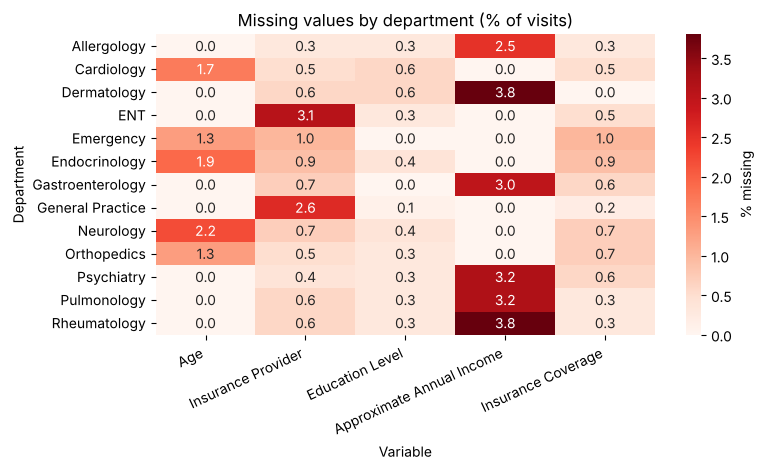

Correlation of missingness indicators (off-diagonal values near 0 = independent gaps):


,Age,Insurance Provider,Education Level,Approximate Annual Income,Insurance Coverage
Age,1.00,0.01,-0.00,-0.01,-0.01
Insurance Provider,0.01,1.00,-0.01,0.00,-0.01
Education Level,-0.00,-0.01,1.00,0.01,0.02
Approximate Annual Income,-0.01,0.00,0.01,1.00,0.01
Insurance Coverage,-0.01,-0.01,0.02,0.01,1.00


In [8]:
miss_cols = [c for c in data_cols if df[c].isna().any()]
rows = []
for c in miss_cols:
    m = df[c].isna()
    per = m.groupby(df["Patient ID"]).agg(["sum", "size"])
    rows.append(dict(variable=c, rows_missing=int(m.sum()),
                     patients_affected=int((per["sum"] > 0).sum()),
                     patients_with_all_visits_missing=int((per["sum"] == per["size"]).sum()),
                     max_share_of_one_patient_visits=round(float((per["sum"] / per["size"]).max()), 2)))
display(pd.DataFrame(rows))

# does missingness relate to the department that recorded the visit?
mr = (df[miss_cols].isna().groupby(df["Department"]).mean() * 100).round(1)
display(mr)

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(mr, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Missing values by department (% of visits)"); ax.set_xlabel("Variable"); ax.set_ylabel("Department")
plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()

# do the gaps coincide in the same rows?
print("Correlation of missingness indicators (off-diagonal values near 0 = independent gaps):")
display(df[miss_cols].isna().corr().round(2))

**Reading the pattern.**
- Gaps are **sparse** (0.3%-1.5% of rows per variable) and almost never overlap: the missingness indicators are uncorrelated, so no visit is "mostly empty".
- Missingness depends on the **recording department**, not on the patient: Age is only missing in five departments, income in six others. This points to a data-capture issue in the source systems, so the true value is not related to the patient's characteristics (consistent with missing completely at random).
- Age, Education and Income are **per-patient attributes** that are present on the patient's other visits. Insurance Provider is entirely missing for just 2 patients, but the coverage amount on each visit identifies the provider (see below).

This justifies imputing from the patient's own other visits rather than from group averages.

<a id="1_3_3"></a>

### 1.3.3 Applying Imputation Strategies

In [9]:
# --- Age and Education: static attributes -> fill from the same patient's other visits (mode) ------------
for col in ["Age", "Education Level"]:
    n = df[col].isna().sum()
    df[col] = df.groupby("Patient ID")[col].transform(
        lambda s: s.fillna(s.mode().iloc[0]) if s.notna().any() else s)
    log(f"Missing {col}", col, n, "Fill with the same patient's value from other visits",
        "Static attribute, always available on other visits of the same patient (no patient entirely missing). "
        f"Residual NaN: {int(df[col].isna().sum())}.")

# --- Insurance provider: every provider pays a fixed share of the price -> infer it from coverage / price ---
ok = (df["Insurance Provider"].notna() & df["Insurance Coverage"].notna() & (df["Consultation Price"] <= 1000))
ratio_tbl = ((df.loc[ok, "Insurance Coverage"] / df.loc[ok, "Consultation Price"])
             .groupby(df.loc[ok, "Insurance Provider"]).agg(["median", "min", "max", "count"]).round(3))
display(ratio_tbl)
RATE = ratio_tbl["median"].round(2).to_dict()          # data-driven coverage rate per provider
assert RATE == {"None": 0.0, "Provider A": 0.8, "Provider B": 0.9, "Provider C": 0.7, "Provider D": 1.0}
STATS["coverage_rates"] = RATE

miss_ins = df["Insurance Provider"].isna()
cov_ratio = df["Insurance Coverage"] / df["Consultation Price"]
usable = miss_ins & cov_ratio.notna() & (df["Consultation Price"] <= 1000)
df.loc[usable, "Insurance Provider"] = cov_ratio[usable].map(lambda r: min(RATE, key=lambda k: abs(RATE[k] - r)))
# fallback: patient's other visits (rows where the ratio cannot be used)
df["Insurance Provider"] = df.groupby("Patient ID")["Insurance Provider"].transform(
    lambda s: s.fillna(s.mode().iloc[0]) if s.notna().any() else s)
log("Missing insurance provider", "Insurance Provider", miss_ins.sum(),
    "Infer from coverage/price ratio (A=80%, B=90%, C=70%, D=100%, None=0%), then from patient's other visits",
    "Coverage equals rate x price on all but 6 insured visits (see 1.4.9), so the ratio identifies the provider. "
    f"Residual NaN: {int(df['Insurance Provider'].isna().sum())}.")

# --- Income: recorded per visit and varies slightly -> keep missing here, patient median in the ABT ----------
STATS["income_missing_rows"] = int(df["Approximate Annual Income"].isna().sum())
log("Missing income", "Approximate Annual Income", STATS["income_missing_rows"],
    "Leave missing at visit level; patient income = median of available visits",
    "Income is recorded per visit and varies (std ~ 9k) so the patient median is more robust; every patient has >= 1 value.")

# --- Insurance coverage: derived amount -> recomputed in 1.4.9 once the price is validated ------------------
print("Missing insurance coverage:", int(df["Insurance Coverage"].isna().sum()), "rows -> recomputed in section 1.4.9")

print("\nRemaining missing values after imputation:")
display(df[data_cols].isna().sum()[lambda s: s > 0].to_frame("n_missing"))

,median,min,max,count
Insurance Provider,,,,
None,0.0,0.0,0.000,1778
Provider A,0.8,0.8,2.789,2001
Provider B,0.9,0.9,1.180,1970
Provider C,0.7,0.7,0.700,1941
Provider D,1.0,1.0,1.502,2150


Missing insurance coverage: 49 rows -> recomputed in section 1.4.9

Remaining missing values after imputation:


,n_missing
Approximate Annual Income,154
Insurance Coverage,49


**Imputation decisions**

| Variable | Strategy | Why |
|---|---|---|
| Age, Education Level | Fill with the patient's own value from other visits | Static per patient and always available; no information is invented. |
| Insurance Provider | Infer from `coverage / price`, fall back to the patient's other visits | Each provider pays a fixed share (A 80%, B 90%, C 70%, D 100%, None 0%), so the ratio is a fingerprint of the provider. |
| Approximate Annual Income | Leave missing per visit; use the patient **median** in the ABT (2.1.1) | Income varies a little from visit to visit; a median is robust and every patient has at least one value. |
| Insurance Coverage | Recompute `rate x price` in 1.4.9 | Deterministic business rule; needs a validated price first. |

The ratio table above shows the evidence: for every provider the minimum equals the median rate (A 0.8, B 0.9, C 0.7, D 1.0, None 0); the few larger maxima are the 6 off-rule rows treated in 1.4.9.

Group-mean imputation was rejected: it would blur genuine differences between patients.

<a id="1_4"></a>

## 1.4 Handle Inconsistent Data

[Back to TOC](#toc)

This section follows the order in which problems can be fixed safely: first impossible values and data types, then the **static** patient attributes (age, income, gender, marital status, profession), then labels, ratings and cross-variable contradictions (including insurance coverage).

<a id="1_4_1"></a>

### 1.4.1 Identifying Inconsistent Data (Negative Values, Incorrect Dates)

In [10]:
num_cols = ["Age", "Consultation Duration", "Satisfaction Level", "Approximate Annual Income",
            "Consultation Price", "Insurance Coverage"]
vd = df["Visit Date"]
audit = pd.DataFrame([
    ("Negative values in any numeric variable", int((df[num_cols] < 0).any(axis=1).sum())),
    ("Visit Date not a valid date (NaT)", int(vd.isna().sum())),
    ("Visit Date outside 1 Jan - 30 Jun 2024", int(((vd < "2024-01-01") | (vd > "2024-06-30")).sum())),
    ("Visit Date after the reference date (1 Jul 2024)", int((vd >= REF_DATE).sum())),
    ("Age impossible for a human (> 110)", int((df["Age"] > 110).sum())),
    ("Consultation Duration <= 0", int((df["Consultation Duration"] <= 0).sum())),
    ("Satisfaction outside the 1-5 scale", int((~df["Satisfaction Level"].between(1, 5)).sum())),
    ("Coverage greater than price (price <= 1000)",
     int(((df["Insurance Coverage"] > df["Consultation Price"]) & (df["Consultation Price"] <= 1000)).sum())),
], columns=["check", "rows_failing"])
display(audit)
print("Visit Date dtype:", vd.dtype, "| weekday coverage:", sorted(vd.dt.dayofweek.unique()))

,check,rows_failing
0,Negative values in any numeric variable,0
1,Visit Date not a valid date (NaT),0
2,Visit Date outside 1 Jan - 30 Jun 2024,0
3,Visit Date after the reference date (1 Jul 2024),0
4,Age impossible for a human (> 110),103
5,Consultation Duration <= 0,0
6,Satisfaction outside the 1-5 scale,719
7,Coverage greater than price (price <= 1000),6


Visit Date dtype: datetime64[us] | weekday coverage: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]


**Findings.** There are **no negative values** and **no invalid or out-of-range dates**: every visit falls between 1 Jan and 30 Jun 2024, before the 1 Jul reference date. The real inconsistencies are impossible magnitudes: ages above 110 and a rating outside the 1-5 scale (handled in 1.4.3 and 1.4.7). Extreme prices, incomes and durations are treated as outliers in section 1.5, and the coverage rule in 1.4.9.

<a id="1_4_2"></a>

### 1.4.2 Correcting Data Types for Optimal Performance

In [11]:
mem_before = df.memory_usage(deep=True).sum() / 1024

assert df["Age"].notna().all()                       # filled in 1.3.3, so it can be an integer now
df["Patient ID"] = df["Patient ID"].astype("int32")
df["Age"] = df["Age"].astype("int16")
df["Consultation Duration"] = df["Consultation Duration"].astype("int16")
df["Satisfaction Level"] = df["Satisfaction Level"].astype("int8")   # promoted to float in 1.4.7 (code 6 -> NaN)
df["Visit Date"] = pd.to_datetime(df["Visit Date"])

CAT_COLS = ["Gender", "City of Residence", "Profession", "Insurance Provider", "Family History",
            "Education Level", "Marital Status", "Department"]
for c in CAT_COLS:
    df[c] = df[c].astype("category")

mem_after = df.memory_usage(deep=True).sum() / 1024
print(f"Memory: {mem_before:,.0f} KB -> {mem_after:,.0f} KB")
display(df.dtypes.to_frame("dtype").T)

Memory: 5,273 KB -> 648 KB


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage,row_id,flag_same_day_same_dept
dtype,int32,int16,category,category,category,category,category,category,category,datetime64[us],category,int16,int8,float64,float64,float64,int64,bool


**Why these types.** `Age` became an integer (no gaps remain), `Patient ID` and the duration/rating columns are downcast to compact integers, `Visit Date` is a true datetime (needed for recency and monthly features), and the eight low-cardinality text columns are `category`, which stores each label once and speeds up grouping. The satisfaction column is temporarily `int8` and is promoted to a float in 1.4.7, once the invalid code becomes a missing value.

<a id="1_4_3"></a>

### 1.4.3 Checking Demographic and Socio-Economic Variables

In [12]:
# Age: impossible values (> 110) are "hundreds-digit" typos (e.g. 138 vs 38 for the same patient)
bad_age = df["Age"] > 110
STATS["bad_age_patients"] = sorted(df.loc[bad_age, "Patient ID"].unique().tolist())
print("Rows with age > 110:", int(bad_age.sum()), "| patients:", STATS["bad_age_patients"])
print("Range of impossible ages:", int(df.loc[bad_age, "Age"].min()), "-", int(df.loc[bad_age, "Age"].max()))
print("\nAges recorded for patient 1198 (mix of valid and impossible values proves a typo):")
print(df.loc[df["Patient ID"] == 1198, "Age"].value_counts().to_string())

df["flag_age_corrected"] = bad_age
df.loc[bad_age, "Age"] = df.loc[bad_age, "Age"] - 100
corrected = sorted(df.loc[bad_age, "Age"].unique().tolist())
log(f"Impossible ages ({int(df.loc[bad_age, 'Age'].add(100).min())}-{int(df.loc[bad_age, 'Age'].add(100).max())})", "Age", bad_age.sum(),
    "Correct: subtract 100 (flag_age_corrected)",
    f"{len(STATS['bad_age_patients'])} patients; patient 1198 has both 38 and 138, proving a typo. Corrected ages {tuple(corrected)} agree "
    "with profession and education (student/high school, retired, master...).")
print("\nCorrected ages:", corrected)
assert df["Age"].between(0, 110).all()

Rows with age > 110: 103 | patients: [1000, 1180, 1198, 1207, 1319]
Range of impossible ages: 118 - 195

Ages recorded for patient 1198 (mix of valid and impossible values proves a typo):
Age
138    21
38      1

Corrected ages: [18, 38, 42, 58, 95]


In [13]:
# Income: zero income - legitimate or an error?  (patient-level view)
pt = df.groupby("Patient ID", observed=True).agg(age=("Age", "median"), prof=("Profession", lambda s: s.mode().iloc[0]),
                                                 inc=("Approximate Annual Income", "median"))
pt["age_group"] = pd.cut(pt["age"], AGE_BINS, labels=AGE_LAB)
zero = pt["inc"] == 0
print(f"Patients with zero median income: {int(zero.sum())} of {len(pt)}")
display(pd.crosstab(pt["age_group"], zero.map({True: "income = 0", False: "income > 0"})))
print("Professions of zero-income patients:", {k: v for k, v in pt.loc[zero, "prof"].value_counts().items() if v})

Patients with zero median income: 110 of 500


inc,income = 0,income > 0
age_group,,
0-17,101,0
18-34,9,75
35-49,0,60
50-64,0,81
65-79,0,81
80+,0,93


Professions of zero-income patients: {'Student': 105, 'Retired': 2, 'Doctor': 1, 'Lawyer': 1, 'Teacher': 1}


**Decisions.**
- **Age:** all ages above 110 are clearly a typo (a stray hundreds digit). Subtracting 100 gives plausible ages that match each patient's profession and education, so the value is **corrected and flagged** (`flag_age_corrected`) instead of deleted.
- **Income:** a value of £0 is **legitimate**: it occurs for every child and for students, who have no income. Zero is kept as a true zero. Extreme positive incomes (scale errors) are handled in 1.5.

<a id="1_4_4"></a>

### 1.4.4 Identifying Inconsistent Patient Attributes (Static Features)

In [14]:
# Attributes that describe the PATIENT should not change between visits.
static_cols = ["Age", "Gender", "City of Residence", "Profession", "Education Level",
               "Marital Status", "Family History", "Insurance Provider"]
conflicts = pd.DataFrame({c: [int((df.groupby("Patient ID", observed=True)[c].nunique() > 1).sum())]
                          for c in static_cols}, index=["patients with >1 value"]).T
display(conflicts)

for c in ["Gender", "Marital Status", "Profession"]:
    pats = df.groupby("Patient ID", observed=True)[c].nunique()
    pats = pats[pats > 1].index
    print(f"\n{c}: visits per label for the {len(pats)} conflicting patients")
    display(df[df["Patient ID"].isin(pats)].groupby(["Patient ID", c], observed=True).size().unstack(fill_value=0))

,patients with >1 value
Age,0
Gender,5
City of Residence,0
Profession,2
Education Level,0
Marital Status,4
Family History,0
Insurance Provider,0



Gender: visits per label for the 5 conflicting patients


Gender,Female,Male
Patient ID,,
1050,14,3
1307,1,23
1349,1,17
1447,18,2
1490,24,3



Marital Status: visits per label for the 4 conflicting patients


Marital Status,Married,Single,Widowed
Patient ID,,,
1140,0,18,1
1322,2,17,0
1332,1,23,0
1382,0,21,1



Profession: visits per label for the 2 conflicting patients


Profession,Retired,Student
Patient ID,,
1488,2,17
1496,13,5


**Findings.** City, family history, education, insurance provider and (after 1.4.3) age are constant for every patient. **Gender, marital status and profession** change between visits for a handful of patients. In most cases the minority label appears in only 1-3 of ~20 visits, which looks like a data-entry error rather than a real change. Profession is special: two young children alternate between *Student* and *Retired*, which cannot both be true.

<a id="1_4_5"></a>

### 1.4.5 Correcting Inconsistencies Across Patient Visits

Rule: a static attribute takes the patient's **most frequent value**. This guarantees one value per patient and avoids conflicts when the visits are aggregated into the ABT.

In [15]:
def mode_fix(col, label):
    """Replace a static attribute by the patient's most frequent value; log the change."""
    g = df.groupby("Patient ID", observed=True)[col]
    patients = g.nunique()[lambda s: s > 1].index
    mode = g.agg(lambda s: s.dropna().mode().iloc[0])
    changed = df[col].notna() & (df[col].astype(str) != df["Patient ID"].map(mode).astype(str))
    per_pat = changed.groupby(df["Patient ID"]).sum()
    minority = per_pat[per_pat > 0]
    log(f"{label} differs between visits of the same patient", col, changed.sum(),
        "Replace by the patient's most frequent value",
        f"{len(patients)} patients; the minority label appears in only {int(minority.min())}-{int(minority.max())} "
        "visits per patient (of ~20), i.e. entry errors.")
    return mode

for col, lab in [("Gender", "Gender"), ("Marital Status", "Marital status")]:
    m = mode_fix(col, lab)
    df[col] = df["Patient ID"].map(m).astype("category")

# Profession: mode, but a child cannot be 'Retired' -> prefer Student if age < 18
prof_mode = df.groupby("Patient ID", observed=True)["Profession"].agg(lambda s: s.mode().iloc[0])
conf = df.groupby("Patient ID", observed=True)["Profession"].nunique() > 1
age_pat = df.groupby("Patient ID", observed=True)["Age"].median()
conf_pats = []
for pid in conf[conf].index:
    labels = set(df.loc[df["Patient ID"] == pid, "Profession"].astype(str))
    if age_pat[pid] < 18 and "Student" in labels:
        prof_mode[pid] = "Student"
        conf_pats.append(int(pid))
chg = df["Profession"].astype(str) != df["Patient ID"].map(prof_mode).astype(str)
log("Profession differs between visits of the same patient", "Profession", chg.sum(),
    "Use most frequent value; if age < 18 and 'Student' present, use Student",
    f"{int(conf.sum())} patients ({', '.join(map(str, conf_pats))}) aged {', '.join(str(int(age_pat[p])) for p in conf_pats)} "
    "alternate between Student and Retired; Student is the only plausible label.")
df["Profession"] = df["Patient ID"].map(prof_mode).astype("category")

after = pd.DataFrame({c: [int((df.groupby("Patient ID", observed=True)[c].nunique() > 1).sum())] for c in static_cols},
                     index=["patients with >1 value after cleaning"]).T
display(after)
assert (after.iloc[:, 0] == 0).all()

,patients with >1 value after cleaning
Age,0
Gender,0
City of Residence,0
Profession,0
Education Level,0
Marital Status,0
Family History,0
Insurance Provider,0


After the correction **every static attribute has exactly one value per patient**, so taking `first()` or `mode()` in the ABT is now safe.

<a id="1_4_6"></a>

### 1.4.6 Identifying Invalid Category Labels

In [16]:
expected = {
    "Gender": {"Male", "Female", "Other"},
    "Insurance Provider": {"Provider A", "Provider B", "Provider C", "Provider D", "None"},
    "Marital Status": {"Single", "Married", "Divorced", "Widowed"},
    "Family History": {"None", "Diabetes", "Cancer", "Heart Disease", "Hypertension"},
    "Education Level": set(EDU),
}
rows = []
for c in CAT_COLS:
    lab = df[c].astype(str)
    stripped = lab.str.strip()
    rows.append(dict(variable=c, n_labels=lab.nunique(),
                     rows_with_extra_spaces=int((lab != stripped).sum()),
                     case_variants=int(lab.nunique() - stripped.str.lower().nunique()),
                     labels_outside_expected=sorted(set(lab) - expected[c]) if c in expected else "n/a (open list)"))
display(pd.DataFrame(rows))

for c in ["City of Residence", "Profession", "Department"]:
    print(f"{c}: {sorted(df[c].astype(str).unique())}")

,variable,n_labels,rows_with_extra_spaces,case_variants,labels_outside_expected
0,Gender,3,0,0,[]
1,City of Residence,8,0,0,n/a (open list)
2,Profession,10,0,0,n/a (open list)
3,Insurance Provider,5,0,0,[]
4,Family History,5,0,0,[]
5,Education Level,8,0,0,[]
6,Marital Status,4,0,0,[]
7,Department,13,0,0,n/a (open list)


City of Residence: ['Belfast', 'Birmingham', 'Dublin', 'Edinburgh', 'Glasgow', 'Liverpool', 'London', 'Manchester']
Profession: ['Artist', 'Businessperson', 'Doctor', 'Engineer', 'Lawyer', 'Nurse', 'Retired', 'Scientist', 'Student', 'Teacher']
Department: ['Allergology', 'Cardiology', 'Dermatology', 'ENT', 'Emergency', 'Endocrinology', 'Gastroenterology', 'General Practice', 'Neurology', 'Orthopedics', 'Psychiatry', 'Pulmonology', 'Rheumatology']


**Result.** No label problems were found: no stray spaces, no upper/lower-case variants, no spelling variants and no label outside the documented domain (e.g. gender is Male/Female/Other, providers are A-D plus `None`). **No relabelling is needed.** The only thing to keep in mind is that `None` is a valid category and the `Other` gender share is large (about a third of patients), which is worth confirming with the data owner.

<a id="1_4_7"></a>

### 1.4.7 Correcting Satisfaction Level Values

In [17]:
print("Raw rating counts:")
display(df["Satisfaction Level"].value_counts().sort_index().to_frame("visits").T)

bad_sat = df["Satisfaction Level"] == 6
print(f"Invalid rating (6): {int(bad_sat.sum())} visits = {bad_sat.mean():.1%}")
print("Where do they come from?  Visits per department with rating 6:")
display(df.loc[bad_sat, "Department"].value_counts().head(6).to_frame("rating_6_visits").T)

df["Satisfaction Level"] = df["Satisfaction Level"].astype(float)
df["flag_rating_invalid"] = bad_sat
df.loc[bad_sat, "Satisfaction Level"] = np.nan
log("Satisfaction rating = 6 (scale is 1-5)", "Satisfaction Level", bad_sat.sum(),
    "Set to missing; excluded from satisfaction averages (n_rated_visits kept)",
    "Out of range; 7% of visits so imputing would invent opinions. Satisfaction features are computed on valid ratings only.")
print("\nValid ratings now:", int(df["Satisfaction Level"].notna().sum()), "| range:",
      df["Satisfaction Level"].min(), "-", df["Satisfaction Level"].max())

Raw rating counts:


Satisfaction Level,1,2,3,4,5,6
visits,1865,1890,1838,1886,1802,719


Invalid rating (6): 719 visits = 7.2%
Where do they come from?  Visits per department with rating 6:


Department,General Practice,ENT,Psychiatry,Dermatology,Pulmonology,Allergology
rating_6_visits,472,243,2,1,1,0



Valid ratings now: 9281 | range: 1.0 - 5.0


**Decision.** A rating of 6 is impossible on a 1-5 scale. It is set to **missing** (not capped to 5, not replaced by a mean) because the patient's real opinion is unknown, and 7% of visits is far too many to invent. Satisfaction features in the ABT are computed on valid ratings only, and `n_rated_visits` / `n_invalid_ratings` keep track of how much evidence each patient has. The invalid codes are concentrated in two departments, which suggests a faulty field in those departments' form rather than random noise.

<a id="1_4_8"></a>

### 1.4.8 Checking Logical Contradictions

In [18]:
# (a) Profession vs age: children who are Doctor/Lawyer/Teacher/Retired, or a 95-year-old student
pa = df.groupby("Patient ID", observed=True).agg(age=("Age", "median"), prof=("Profession", lambda s: s.mode().iloc[0]))
odd = pa[((pa.age < 18) & (pa.prof != "Student")) | ((pa.age > 65) & (pa.prof == "Student"))]
display(odd.rename(columns={"age": "median_age", "prof": "profession"}))
df["flag_profession_age_odd"] = df["Patient ID"].isin(odd.index)
log("Profession implausible for age (child 'Doctor/Lawyer/Teacher/Retired'; 118-yr-old student)", "Profession",
    df["flag_profession_age_odd"].sum(), "Keep, flag patient (profession_age_odd) and rely on age_group for segmentation",
    f"{len(odd)} patients; label is constant across their visits so cannot be repaired from the data; "
    "removing patients is not justified.")

# (b) Education vs age: does the education level fit the patient's age?
pe = df.groupby("Patient ID", observed=True).agg(age=("Age", "median"), edu=("Education Level", lambda s: s.mode().iloc[0]))
pe["age_group"] = pd.cut(pe["age"], [-1, 5, 11, 17, 34, 200], labels=["0-5", "6-11", "12-17", "18-34", "35+"])
print("\nEducation level by age group (patients):")
display(pd.crosstab(pe["age_group"], pe["edu"])[[e for e in EDU if e in set(pe["edu"])]])

# (c) one insurance provider per patient (insurance is a patient-level attribute)
n_multi = int((df.groupby("Patient ID", observed=True)["Insurance Provider"].nunique() > 1).sum())
STATS["patients_multi_insurance_after"] = n_multi
print("Patients with more than one insurance provider:", n_multi)
print("Visit rows already flagged as same patient/date/department:", int(df["flag_same_day_same_dept"].sum()))

,median_age,profession
Patient ID,,
1181,1.0,Lawyer
1398,5.0,Doctor
1433,9.0,Teacher
1479,11.0,Retired



Education level by age group (patients):


edu,Kindergarten,Pre-school,Elementary school,Middle school/junior high,High school,Undergraduate,Master,PhD
age_group,,,,,,,,
0-5,6,22,0,0,0,0,0,0
6-11,5,0,13,11,0,0,0,0
12-17,0,0,0,19,25,0,0,0
18-34,0,0,0,0,9,39,31,5
35+,0,0,0,0,0,172,138,5


Patients with more than one insurance provider: 0
Visit rows already flagged as same patient/date/department: 114


**Findings.**
- **Profession vs age:** 4 patients (aged 1-11) are recorded as Lawyer, Doctor, Teacher or Retired. The label is the same on every visit, so it cannot be repaired from the data. Decision: **keep and flag** (`profession_age_odd`) and use `age_group` instead of `profession` for segmentation. Removing the patients is not justified because their visits are otherwise valid.
- **Education vs age:** education stages follow age (kindergarten/pre-school for the youngest, elementary and middle school for 6-11, middle/high school for teenagers, university from 18), so no contradiction.
- **Insurance:** every patient has exactly one provider.
- **Same-day visits** were already flagged in 1.2.2.

<a id="1_4_9"></a>

### 1.4.9 Checking Invalid Insurance Coverages

In [19]:
def rate_of(provider):
    return provider.astype(str).map(RATE).astype(float)

price, cov = df["Consultation Price"], df["Insurance Coverage"]
exp_cov = price * rate_of(df["Insurance Provider"])
valid_price = price <= 1000                      # prices above this are scale errors (see 1.5)

# (a) coverage that contradicts the price: the 7 rows with a huge price are NOT bad coverage - the PRICE is wrong
contra = df.loc[~valid_price, ["Patient ID", "Department", "Insurance Provider", "Consultation Price", "Insurance Coverage"]].copy()
contra["coverage_over_price"] = (contra["Insurance Coverage"] / contra["Consultation Price"]).round(4)
contra["expected_rate"] = rate_of(contra["Insurance Provider"])
print("Rows whose price is >1000. For the two insured rows, coverage/price is ~100x below the provider rate (0.008 vs 0.8; 0.007 vs 0.7): the PRICE is wrong, not the coverage")
display(contra)

# (b) rule check on all rows with a plausible price
miss_cov = cov.isna()
tol = 0.01 * price + 0.01
inconsistent = valid_price & ~miss_cov & ((cov - exp_cov).abs() > tol)
print(f"\nRows obeying 'coverage = rate x price': {int((valid_price & ~miss_cov & ~inconsistent).sum())}")
print(f"Missing coverage: {int(miss_cov.sum())} | coverage off the provider rate: {int(inconsistent.sum())}"
      f" (of which > price: {int((cov > price)[inconsistent].sum())})")
display(df.loc[inconsistent, ["Patient ID", "Insurance Provider", "Consultation Price", "Insurance Coverage"]]
        .assign(expected=exp_cov[inconsistent].round(2)).head(8))

# (c) repair: recompute coverage = provider rate x price where it is missing or off the rule
fix = (miss_cov | inconsistent) & valid_price
df["flag_coverage_recomputed"] = fix
df.loc[fix, "Insurance Coverage"] = exp_cov[fix]
log("Missing insurance coverage", "Insurance Coverage", miss_cov.sum(),
    "Recompute = provider rate x price (flag_coverage_recomputed)",
    f"Deterministic business rule observed in all {int((valid_price & ~miss_cov & ~inconsistent).sum()):,} valid rows.")
log("Coverage greater than price or off the provider rate", "Insurance Coverage", inconsistent.sum(),
    "Recompute = provider rate x price",
    f"{int((cov > price)[inconsistent].sum())} rows with coverage > price (impossible) and the rest off the provider rate; "
    "the rule is exact elsewhere.")

Rows whose price is >1000. For the two insured rows, coverage/price is ~100x below the provider rate (0.008 vs 0.8; 0.007 vs 0.7): the PRICE is wrong, not the coverage


,Patient ID,Department,Insurance Provider,Consultation Price,Insurance Coverage,coverage_over_price,expected_rate
333,1373,Endocrinology,None,26399.893442,0.000000,0.000,0.0
575,1313,Neurology,None,25899.550725,0.000000,0.000,0.0
660,1292,Emergency,None,39999.222018,0.000000,0.000,0.0
1685,1029,Neurology,None,26799.937054,0.000000,0.000,0.0
1777,1005,Emergency,None,39400.177964,0.000000,0.000,0.0
3189,1175,Emergency,Provider A,39999.176745,319.341396,0.008,0.8
5997,1445,Cardiology,Provider C,25300.794249,177.655974,0.007,0.7



Rows obeying 'coverage = rate x price': 9938
Missing coverage: 49 | coverage off the provider rate: 6 (of which > price: 6)


,Patient ID,Insurance Provider,Consultation Price,Insurance Coverage,expected
3088,1211,Provider A,50.287175,140.229740,40.23
4338,1344,Provider B,357.653151,421.887836,321.89
5761,1021,Provider B,50.047001,55.042301,45.04
8034,1443,Provider D,83.232090,93.232090,83.23
9010,1230,Provider D,396.312644,400.312644,396.31
9822,1028,Provider D,199.216286,299.216286,199.22


**Decision.** Insurance coverage follows an exact rule (`coverage = provider rate x price`) on every valid row, so missing or off-rule values are **recomputed** rather than imputed with an average, and flagged in `flag_coverage_recomputed`. The seven rows with a price above £1,000 are *not* edited here: for the two insured rows the coverage is exactly what a price 100x smaller would give, which is the evidence that the **price** carries a x100 error (fixed in 1.5.3, where the rule is re-checked on every row).

<a id="1_5"></a>

## 1.5 Identifying and Handling Outliers

[Back to TOC](#toc)

<a id="1_5_1"></a>

### 1.5.1 Detecting Outliers in Numerical Variables

Two complementary tests: the statistical **IQR rule** (1.5 x IQR) and **domain rules** (what is physically/commercially possible).

In [20]:
num = ["Age", "Consultation Duration", "Approximate Annual Income", "Consultation Price", "Insurance Coverage"]
rows = []
for c in num:
    s = df[c].dropna().astype(float)
    q1, q3 = s.quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append(dict(variable=c, min=s.min(), median=s.median(), p99_9=s.quantile(.999), max=s.max(),
                     iqr_low_fence=round(lo, 1), iqr_high_fence=round(hi, 1),
                     n_outside_iqr_fences=int(((s < lo) | (s > hi)).sum())))
display(pd.DataFrame(rows).round(1))

# domain evidence ----------------------------------------------------------------------------------------
print("Consultation Duration: the 12 largest distinct values (note the jump after 120):")
print([int(v) for v in sorted(df["Consultation Duration"].unique())[-12:]])

band = df[df["Consultation Price"] <= 1000].groupby("Department", observed=True)["Consultation Price"].agg(["min", "max"]).round(0)
print("\nNormal price band per department (price <= 1000):")
display(band.T)

pb = df[df["Consultation Price"] > 1000][["Patient ID", "Department", "Consultation Price"]].copy()
pb["price_div_100"] = (pb["Consultation Price"] / 100).round(1)
pb["dept_band_max"] = pb["Department"].astype(str).map(band["max"].to_dict())
print("\nPrices > 1000 (candidate x100 scale errors):")
display(pb)

inc = df["Approximate Annual Income"]
others = df[inc < 1_000_000].groupby("Patient ID")["Approximate Annual Income"].agg(other_visits_min="min", other_visits_max="max")
ib = df.loc[inc >= 1_000_000, ["Patient ID", "Approximate Annual Income"]].rename(columns={"Approximate Annual Income": "income"}).copy()
ib["divide_by_10"] = (ib["income"] / 10).round(0)
ib["divide_by_100"] = (ib["income"] / 100).round(0)
ib = ib.join(others.round(0), on="Patient ID")
print(f"Incomes >= 1,000,000: {len(ib)} rows from {ib['Patient ID'].nunique()} patients. "
      "Candidate corrections vs the range of the same patient's other visits:")
display(ib.sort_values(["Patient ID", "income"]).reset_index(drop=True))
print("Incomes in the rest of the data: max =", f"{int(inc[inc < 1_000_000].max()):,}")

,variable,min,median,p99_9,max,iqr_low_fence,iqr_high_fence,n_outside_iqr_fences
0,Age,0.0,51.0,100.0,100.0,-53.5,150.5,0
1,Consultation Duration,15.0,68.0,120.1,600.0,-38.5,173.5,10
2,Approximate Annual Income,0.0,40890.5,1175583.6,11970900.0,1813.1,80072.1,2285
3,Consultation Price,50.0,159.5,397.9,39999.2,-21.5,332.6,240
4,Insurance Coverage,0.0,116.0,392.9,398.6,-100.1,325.3,76


Consultation Duration: the 12 largest distinct values (note the jump after 120):
[118, 119, 120, 228, 240, 256, 327, 329, 340, 445, 549, 600]

Normal price band per department (price <= 1000):


Department,Allergology,Cardiology,Dermatology,ENT,Emergency,Endocrinology,Gastroenterology,General Practice,Neurology,Orthopedics,Psychiatry,Pulmonology,Rheumatology
min,100.0,150.0,100.0,50.0,200.0,150.0,100.0,50.0,150.0,150.0,100.0,100.0,100.0
max,200.0,300.0,200.0,100.0,399.0,300.0,200.0,100.0,300.0,300.0,200.0,200.0,200.0



Prices > 1000 (candidate x100 scale errors):


,Patient ID,Department,Consultation Price,price_div_100,dept_band_max
333,1373,Endocrinology,26399.893442,264.0,300.0
575,1313,Neurology,25899.550725,259.0,300.0
660,1292,Emergency,39999.222018,400.0,399.0
1685,1029,Neurology,26799.937054,268.0,300.0
1777,1005,Emergency,39400.177964,394.0,399.0
3189,1175,Emergency,39999.176745,400.0,399.0
5997,1445,Cardiology,25300.794249,253.0,300.0


Incomes >= 1,000,000: 21 rows from 10 patients. Candidate corrections vs the range of the same patient's other visits:


,Patient ID,income,divide_by_10,divide_by_100,other_visits_min,other_visits_max
0,1087,1153050.0,115305.0,11530.0,53057.0,112056.0
1,1087,1154440.0,115444.0,11544.0,53057.0,112056.0
2,1088,1182980.0,118298.0,11830.0,52569.0,108955.0
3,1088,11961100.0,1196110.0,119611.0,52569.0,108955.0
4,1157,1147930.0,114793.0,11479.0,54009.0,111353.0
5,1157,1180910.0,118091.0,11809.0,54009.0,111353.0
6,1157,11885100.0,1188510.0,118851.0,54009.0,111353.0
7,1230,1146720.0,114672.0,11467.0,54319.0,110509.0
8,1230,1156970.0,115697.0,11570.0,54319.0,110509.0
9,1265,1163140.0,116314.0,11631.0,50327.0,112246.0


Incomes in the rest of the data: max = 113,120


**Reading the tests.** The IQR rule is only reliable for **duration** (it flags exactly the 10 extreme rows). For **price** it also flags 240 normal Emergency/Cardiology visits, because prices legitimately differ by department (the pooled quartiles are not appropriate), and for **income** it flags 2,285 rows because zero income for children and students makes the distribution highly skewed. For these two variables the domain evidence decides: every normal price lies inside its department's band (£50-£400) and no income outside the 7 + 21 extreme rows exceeds about £113k. A price above £1,000 or an income of £1M or more is therefore an error, not a rare patient.

For income, dividing by 10 (1.0-9.9M) or by 100 (>= 10M) gives £113k-£120k. This lands at the top of the same patient's own range (other visits about £50k-£113k) while the other divisor would give about £11-12k, far below it, so it identifies the intended value.

<a id="1_5_2"></a>

### 1.5.2 Visualizing Potential Outliers

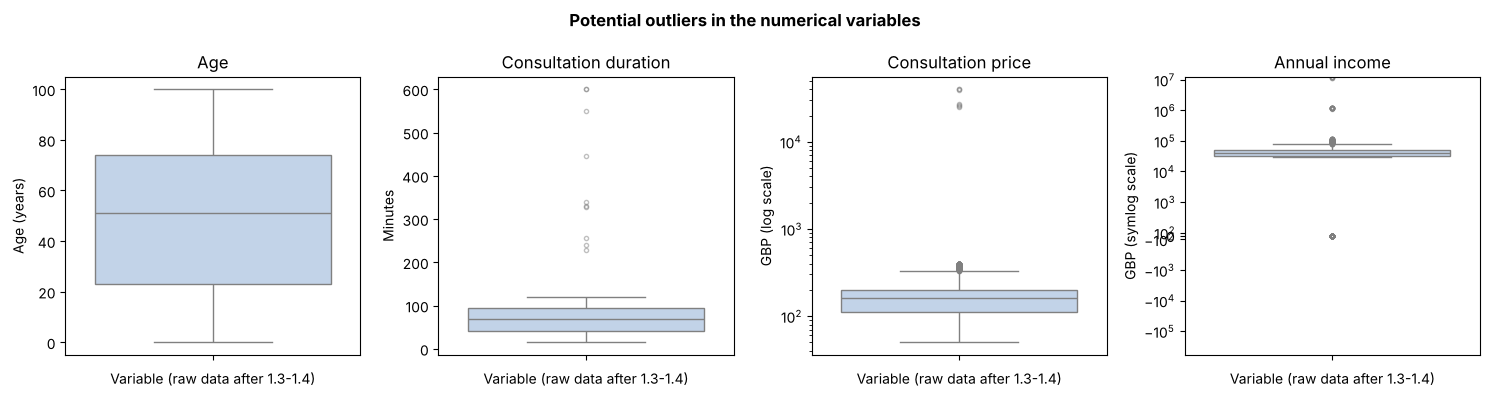

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
specs = [("Age", None, "Age (years)", "Age"),
         ("Consultation Duration", None, "Minutes", "Consultation duration"),
         ("Consultation Price", "log", "GBP (log scale)", "Consultation price"),
         ("Approximate Annual Income", "symlog", "GBP (symlog scale)", "Annual income")]
for ax, (c, scale, ylab, title) in zip(axes, specs):
    sns.boxplot(y=df[c].dropna().astype(float), ax=ax, color="#bcd3ee", flierprops=dict(marker="o", markersize=3, alpha=.5))
    if scale == "log":
        ax.set_yscale("log")
    elif scale == "symlog":
        ax.set_yscale("symlog", linthresh=1000)
    ax.set_title(title); ax.set_ylabel(ylab); ax.set_xlabel("Variable (raw data after 1.3-1.4)")
fig.suptitle("Potential outliers in the numerical variables", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretation.** Each variable has a compact bulk of plausible values and a few points that are orders of magnitude away: prices of £25,000-£40,000 (normal range £50-£400), incomes of £1M-£12M (normal range £0-£115k) and durations of 228-600 minutes (all other visits last 15-120 minutes). Ages are already clean after 1.4.3. The extremes are not gradual tails but **isolated, far-away values**, a typical sign of entry or scale errors rather than genuine patients.

<a id="1_5_3"></a>

### 1.5.3 Deciding How to Handle Outliers

In [22]:
# --- Price: x100 scale errors -> divide by 100 ----------------------------------------------------------------
bad_price = df["Consultation Price"] > 1000
df["flag_price_corrected"] = bad_price
df.loc[bad_price, "Consultation Price"] = df.loc[bad_price, "Consultation Price"] / 100
log("Consultation price x100 (25,300-39,999 GBP)", "Consultation Price", bad_price.sum(),
    "Correct: divide by 100 (flag_price_corrected)",
    "Corrected values fall exactly inside the price band of their department (e.g. Emergency 200-400), "
    "so this is a decimal-scale error, not a real price.")

# --- Income: x10 / x100 scale errors; zeros are legitimate (children/students) -------------------------------
inc = df["Approximate Annual Income"]
bad_inc = inc >= 1_000_000
df["flag_income_corrected"] = bad_inc
df.loc[inc >= 10_000_000, "Approximate Annual Income"] = inc / 100
df.loc[(inc >= 1_000_000) & (inc < 10_000_000), "Approximate Annual Income"] = inc / 10
log("Income x10 / x100 (1.0M-12.0M)", "Approximate Annual Income", bad_inc.sum(),
    "Correct: /10 (1.0-9.9M) or /100 (>=10M), flag_income_corrected",
    "Corrected values (113k-120k) sit at the top of the same patient's own range (other visits ~50k-113k), while the other "
    "divisor would give ~11-12k, far below it. Zero income (children and students) is kept as true zero.")

# --- Duration: max plausible 120 min -> department median -----------------------------------------------------
bad_dur = df["Consultation Duration"] > 120
df["flag_duration_imputed"] = bad_dur
med_dur = df.loc[~bad_dur].groupby("Department", observed=True)["Consultation Duration"].median().round()
fill = df.loc[bad_dur, "Department"].astype(str).map(med_dur.to_dict()).astype("int16")
df.loc[bad_dur, "Consultation Duration"] = fill
log("Implausible durations (228-600 min)", "Consultation Duration", bad_dur.sum(),
    "Impute with department median (flag_duration_imputed)",
    "All other visits lie in 15-120 min; the outliers are not a constant scale error so the true value is unknown.")

print(f"Corrected prices: {int(bad_price.sum())} | corrected incomes: {int(bad_inc.sum())} | imputed durations: {int(bad_dur.sum())}")

Corrected prices: 7 | corrected incomes: 21 | imputed durations: 10


**Decisions: correct when the error has a recoverable pattern, impute when it does not, never delete.**

| Variable | Outlier | Decision | Reason |
|---|---|---|---|
| Consultation Price | 7 rows of £25k-£40k | Divide by 100 and flag | Result lands exactly inside the department's normal price band, and for the two insured rows the (correct) coverage already implied a normal price. |
| Annual Income | 21 rows of £1M-£12M | Divide by 10 (1.0-9.9M) or 100 (>= 10M) and flag | Gives £113k-£120k, at the top of the same patient's own range (other visits about £50k-£113k); the other divisor would give about £11-12k, far outside it. |
| Consultation Duration | 10 rows of 228-600 min | Impute department median and flag | All other visits are 15-120 min; the extremes are not a constant multiple of a plausible value, so the true duration is unknown. |
| Age | already corrected in 1.4.3 | - | - |
| Zero income | 110 patients | Keep | Children and students legitimately earn nothing. |

In [23]:
# --- Final validation: rules re-checked on every row after all corrections ------------------------------------
exp_cov = df["Consultation Price"] * rate_of(df["Insurance Provider"])
dev = (df["Insurance Coverage"] - exp_cov).abs()
assert (dev <= 0.01 * df["Consultation Price"] + 0.01).all()          # coverage = rate x price (incl. the 7 price fixes)
assert df["Age"].between(0, 110).all()
assert df["Consultation Price"].between(50, 400).all()
assert df["Consultation Duration"].between(15, 120).all()
assert (df["Insurance Coverage"] <= df["Consultation Price"] + 1e-6).all()
assert df["Visit Date"].between("2024-01-01", "2024-06-30").all()
assert df["Approximate Annual Income"].dropna().between(0, 250_000).all()

# derived visit-level columns used by the ABT and the charts
for c in CAT_COLS:
    df[c] = df[c].astype("category")                   # dtypes may have been reset by the corrections above
df["out_of_pocket"] = df["Consultation Price"] - df["Insurance Coverage"]
df["Month"] = df["Visit Date"].dt.to_period("M").dt.to_timestamp()
df["age_group"] = pd.cut(df["Age"], AGE_BINS, labels=AGE_LAB)

df.drop(columns="row_id").to_csv("visit_level_clean.csv", index=False)
STATS["clean_rows"] = len(df)
STATS["clean_patients"] = int(df["Patient ID"].nunique())
STATS["rows_per_patient"] = df.groupby("Patient ID").size().describe().round(2).to_dict()
print(f"All validation rules pass. Clean visits: {len(df):,} | patients: {STATS['clean_patients']}")

All validation rules pass. Clean visits: 10,000 | patients: 500


**Summary of all cleaning decisions** (also saved as `cleaning_log.csv`):

In [24]:
display(pd.DataFrame(LOG)[["issue", "variable", "rows_affected", "decision"]])

,issue,variable,rows_affected,decision
0,'None' category read as missing by default,"Insurance Provider, Family History",3799,Keep 'None' as a valid category (read with keep_default_na=False)
1,Exact duplicate visits (all 16 fields identical),all,8,Remove (keep first)
2,"Same patient, date and department but different duration/rating/price",Visit rows,114,Keep and flag (flag_same_day_same_dept)
3,Missing Age,Age,56,Fill with the same patient's value from other visits
4,Missing Education Level,Education Level,29,Fill with the same patient's value from other visits
5,Missing insurance provider,Insurance Provider,104,"Infer from coverage/price ratio (A=80%, B=90%, C=70%, D=100%, None=0%), then from pati..."
6,Missing income,Approximate Annual Income,154,Leave missing at visit level; patient income = median of available visits
7,Impossible ages (118-195),Age,103,Correct: subtract 100 (flag_age_corrected)
8,Gender differs between visits of the same patient,Gender,10,Replace by the patient's most frequent value
9,Marital status differs between visits of the same patient,Marital Status,5,Replace by the patient's most frequent value


<a id="2"></a>

# 2. Part B - Feature Engineering & ABT Construction

[Back to TOC](#toc)

One row per `Patient ID`. Features are grouped as **static**, **visit behaviour**, **financial**, **satisfaction**, **recency & activity** (reference date 1 July 2024) and **data-quality flags**. Because every static attribute now has a single value per patient (1.4.5), aggregating with `first()` is safe.

<a id="2_1"></a>

## 2.1 Patient-Level ABT Construction

[Back to TOC](#toc)

In [25]:
g = df.groupby("Patient ID", observed=True)
dept_s = df["Department"].astype(str)                  # plain strings for the department logic
abt = pd.DataFrame(index=g.size().index)
abt.index.name = "patient_id"

<a id="2_1_1"></a>

### 2.1.1 Static Attributes

In [26]:
abt["age"] = g["Age"].first().astype(int)
abt["age_group"] = pd.cut(abt["age"], AGE_BINS, labels=AGE_LAB).astype(str)
abt["gender"] = g["Gender"].first().astype(str)
abt["city"] = g["City of Residence"].first().astype(str)
abt["profession"] = g["Profession"].first().astype(str)
abt["education_level"] = g["Education Level"].first().astype(str)
abt["education_ordinal"] = abt["education_level"].map({k: i for i, k in enumerate(EDU)})
abt["marital_status"] = g["Marital Status"].first().astype(str)
abt["family_history"] = g["Family History"].first().astype(str)
abt["has_family_history"] = (abt["family_history"] != "None").astype(int)
abt["insurance_provider"] = g["Insurance Provider"].agg(lambda s: s.mode().iloc[0]).astype(str)
abt["has_insurance"] = (abt["insurance_provider"] != "None").astype(int)
abt["insurance_coverage_rate"] = abt["insurance_provider"].map(RATE)
abt["annual_income"] = g["Approximate Annual Income"].median().round(0)
abt["income_std"] = g["Approximate Annual Income"].std().round(0)
assert abt["annual_income"].notna().all()
display(abt.head(3))

,age,age_group,gender,city,profession,education_level,education_ordinal,marital_status,family_history,has_family_history,insurance_provider,has_insurance,insurance_coverage_rate,annual_income,income_std
patient_id,,,,,,,,,,,,,,,
1000,58,50-64,Female,Birmingham,Artist,Undergraduate,5,Divorced,Hypertension,1,Provider D,1,1.0,45692.0,9711.0
1001,55,50-64,Male,Liverpool,Lawyer,Undergraduate,5,Married,Heart Disease,1,Provider C,1,0.7,41338.0,8514.0
1002,10,0-17,Female,Liverpool,Student,Elementary school,2,Single,Cancer,1,Provider C,1,0.7,0.0,0.0


<a id="2_1_2"></a>

### 2.1.2 Visit Behaviour Features

In [27]:
gd = dept_s.groupby(df["Patient ID"])
abt["n_visits"] = g.size()
abt["n_distinct_departments"] = gd.nunique()
abt["top_department"] = gd.agg(lambda s: s.value_counts(sort=False).idxmax())   # ties: first department seen
abt["top_department_share"] = (gd.agg(lambda s: s.value_counts(sort=False).max()) / abt["n_visits"]).round(4)
abt["avg_duration_min"] = g["Consultation Duration"].mean().round(2)
abt["std_duration_min"] = g["Consultation Duration"].std().round(2)
abt["total_duration_min"] = g["Consultation Duration"].sum()
abt["n_emergency_visits"] = gd.agg(lambda s: (s == "Emergency").sum())
abt["share_emergency"] = (abt["n_emergency_visits"] / abt["n_visits"]).round(4)
dept_counts = pd.crosstab(df["Patient ID"], dept_s)
dept_counts.columns = ["visits_" + c.lower().replace(" ", "_") for c in dept_counts.columns]
abt = abt.join(dept_counts)
display(abt[["n_visits", "n_distinct_departments", "top_department", "top_department_share", "avg_duration_min"]].head(3))

,n_visits,n_distinct_departments,top_department,top_department_share,avg_duration_min
patient_id,,,,,
1000,20,10,Allergology,0.1500,65.70
1001,16,10,ENT,0.1875,60.50
1002,18,10,Psychiatry,0.2778,71.06


<a id="2_1_3"></a>

### 2.1.3 Financial Features

In [28]:
abt["total_price"] = g["Consultation Price"].sum().round(2)
abt["avg_price"] = g["Consultation Price"].mean().round(2)
abt["total_insurance_coverage"] = g["Insurance Coverage"].sum().round(2)
abt["avg_insurance_coverage"] = g["Insurance Coverage"].mean().round(2)
abt["total_out_of_pocket"] = g["out_of_pocket"].sum().round(2)       # out-of-pocket = price - coverage
abt["avg_out_of_pocket"] = g["out_of_pocket"].mean().round(2)
abt["coverage_share"] = (abt["total_insurance_coverage"] / abt["total_price"]).round(4)
abt["oop_to_income_pct"] = np.where(abt["annual_income"] > 0,
                                    (abt["total_out_of_pocket"] / abt["annual_income"].replace(0, np.nan) * 100).round(3), np.nan)
display(abt[["total_price", "avg_price", "total_insurance_coverage", "total_out_of_pocket", "coverage_share"]].head(3))

,total_price,avg_price,total_insurance_coverage,total_out_of_pocket,coverage_share
patient_id,,,,,
1000,3504.03,175.20,3504.03,0.00,1.0
1001,2396.99,149.81,1677.89,719.10,0.7
1002,2919.25,162.18,2043.48,875.78,0.7


<a id="2_1_4"></a>

### 2.1.4 Satisfaction Features

In [29]:
s = g["Satisfaction Level"]                                    # valid ratings only (code 6 is NaN)
abt["avg_satisfaction"] = s.mean().round(3)
abt["min_satisfaction"] = s.min()
abt["max_satisfaction"] = s.max()
abt["std_satisfaction"] = s.std().round(3)
abt["n_rated_visits"] = s.count()
abt["share_low_ratings"] = (s.agg(lambda x: (x <= 2).sum()) / abt["n_rated_visits"]).round(4)
abt["share_high_ratings"] = (s.agg(lambda x: (x >= 4).sum()) / abt["n_rated_visits"]).round(4)
abt["n_invalid_ratings"] = g["flag_rating_invalid"].sum()
display(abt[["avg_satisfaction", "min_satisfaction", "share_low_ratings", "n_rated_visits", "n_invalid_ratings"]].head(3))

,avg_satisfaction,min_satisfaction,share_low_ratings,n_rated_visits,n_invalid_ratings
patient_id,,,,,
1000,2.600,1.0,0.5000,20,0
1001,2.769,1.0,0.4615,13,3
1002,3.353,1.0,0.2353,17,1


<a id="2_1_5"></a>

### 2.1.5 Recency and Activity Features

In [30]:
last = g["Visit Date"].max()
first = g["Visit Date"].min()
abt["days_since_last_visit"] = (REF_DATE - last).dt.days
abt["days_since_first_visit"] = (REF_DATE - first).dt.days
abt["observation_months"] = (abt["days_since_first_visit"] / 30.4375).round(3)
abt["visits_per_month"] = (abt["n_visits"] / abt["observation_months"]).round(3)
abt["avg_days_between_visits"] = ((last - first).dt.days / (abt["n_visits"] - 1)).round(2)
q1 = df[df["Visit Date"] < "2024-04-01"].groupby("Patient ID").size()
abt["visits_q1"] = q1.reindex(abt.index).fillna(0).astype(int)
abt["visits_q2"] = abt["n_visits"] - abt["visits_q1"]
abt["visit_trend_q2_minus_q1"] = abt["visits_q2"] - abt["visits_q1"]
display(abt[["days_since_last_visit", "days_since_first_visit", "visits_per_month", "visits_q1", "visits_q2"]].head(3))

,days_since_last_visit,days_since_first_visit,visits_per_month,visits_q1,visits_q2
patient_id,,,,,
1000,4,182,3.345,11,9
1001,4,181,2.690,10,6
1002,8,177,3.095,10,8


**Data-quality flags (patient level).** Besides the business features, the ABT keeps a few flags so the next team can exclude or investigate patients whose data was repaired.

In [31]:
for c, n in [("flag_age_corrected", "dq_age_corrected"), ("flag_price_corrected", "dq_price_corrected"),
             ("flag_income_corrected", "dq_income_corrected"), ("flag_profession_age_odd", "profession_age_odd")]:
    abt[n] = g[c].max().astype(int)
flag_cols = ["flag_duration_imputed", "flag_coverage_recomputed", "flag_rating_invalid",
             "flag_price_corrected", "flag_income_corrected"]
abt["dq_n_flagged_visits"] = df.assign(_f=df[flag_cols].any(axis=1)).groupby("Patient ID")["_f"].sum()

abt = abt.reset_index()
assert abt["patient_id"].is_unique and len(abt) == 500
STATS["abt_shape"] = list(abt.shape)
STATS["abt_nan"] = {k: int(v) for k, v in abt.isna().sum().items() if v}
print("ABT shape:", abt.shape, "| one row per patient:", abt["patient_id"].is_unique)
print("Columns with missing values:", STATS["abt_nan"])

ABT shape: (500, 67) | one row per patient: True
Columns with missing values: {'oop_to_income_pct': 110}


The only remaining missing values are structural: `oop_to_income_pct` is undefined when income is zero (children/students) and `std_*` features are undefined for patients with a single valid observation. They are left as NaN on purpose, because a fake value would mislead a model.

<a id="2_2"></a>

## 2.2 Data Dictionary

[Back to TOC](#toc)

In [32]:
D = []
def d(name, group, definition, calc):
    D.append(dict(feature=name, group=group, definition=definition, calculation=calc))

d("patient_id", "Key", "Unique patient identifier", "Patient ID")
d("age", "Static", "Age in years", "Patient's age (typos >110 corrected by -100; gaps filled from other visits)")
d("age_group", "Static", "Age band", "Bins 0-17, 18-34, 35-49, 50-64, 65-79, 80+")
d("gender", "Static", "Gender", "Most frequent label across the patient's visits")
d("city", "Static", "City of residence", "Constant per patient")
d("profession", "Static", "Profession", "Most frequent label (Student if age<18 and conflict)")
d("education_level", "Static", "Highest education", "Constant per patient; gaps filled from other visits")
d("education_ordinal", "Static", "Ordinal education 0-7", "Kindergarten=0 ... PhD=7")
d("marital_status", "Static", "Marital status", "Most frequent label across visits")
d("family_history", "Static", "Family disease history (None/Diabetes/Cancer/Heart Disease/Hypertension)", "Constant per patient")
d("has_family_history", "Static", "1 if any family disease", "family_history != 'None'")
d("insurance_provider", "Static", "Insurance provider (None, A-D)", "Mode over visits; missing inferred from coverage/price ratio")
d("has_insurance", "Static", "1 if insured", "insurance_provider != 'None'")
d("insurance_coverage_rate", "Static", "Share of price paid by insurer", "A=0.8, B=0.9, C=0.7, D=1.0, None=0 (observed rule)")
d("annual_income", "Static", "Approximate annual income (GBP)", "Median of the patient's visit-level incomes after scale correction")
d("income_std", "Static", "Variability of recorded income", "Std of visit-level income")
d("n_visits", "Behaviour", "Number of consultations Jan-Jun 2024", "Row count per patient (after de-duplication)")
d("n_distinct_departments", "Behaviour", "Different departments visited", "nunique(Department)")
d("top_department", "Behaviour", "Most frequent department", "Mode of Department (first in count order on ties)")
d("top_department_share", "Behaviour", "Share of visits in top department", "visits in top dept / n_visits")
d("avg_duration_min", "Behaviour", "Average consultation length (min)", "mean(Consultation Duration)")
d("std_duration_min", "Behaviour", "Std of consultation length", "std(Consultation Duration)")
d("total_duration_min", "Behaviour", "Total minutes with the hospital", "sum(Consultation Duration)")
d("n_emergency_visits", "Behaviour", "Emergency visits", "count(Department=='Emergency')")
d("share_emergency", "Behaviour", "Share of visits in Emergency", "n_emergency_visits / n_visits")
d("visits_<department> (13 cols)", "Behaviour", "Visits per department", "Crosstab patient x department")
d("total_price", "Financial", "Total price of all consultations (GBP)", "sum(Consultation Price)")
d("avg_price", "Financial", "Average price per consultation", "mean(Consultation Price)")
d("total_insurance_coverage", "Financial", "Total paid by insurer", "sum(Insurance Coverage)")
d("avg_insurance_coverage", "Financial", "Average coverage per visit", "mean(Insurance Coverage)")
d("total_out_of_pocket", "Financial", "Total paid by patient", "sum(price - coverage)")
d("avg_out_of_pocket", "Financial", "Average out-of-pocket per visit", "mean(price - coverage)")
d("coverage_share", "Financial", "Share of cost covered by insurance", "total_insurance_coverage / total_price")
d("oop_to_income_pct", "Financial", "Out-of-pocket as % of annual income", "total_out_of_pocket / annual_income *100 (NaN if income = 0)")
d("avg_satisfaction", "Satisfaction", "Mean rating (1-5)", "mean of valid ratings (code 6 excluded)")
d("min_satisfaction", "Satisfaction", "Lowest rating", "min of valid ratings")
d("max_satisfaction", "Satisfaction", "Highest rating", "max of valid ratings")
d("std_satisfaction", "Satisfaction", "Rating variability", "std of valid ratings")
d("n_rated_visits", "Satisfaction", "Visits with a valid rating", "count of valid ratings")
d("share_low_ratings", "Satisfaction", "Share of low ratings (<=2)", "visits rated 1-2 / n_rated_visits")
d("share_high_ratings", "Satisfaction", "Share of high ratings (>=4)", "visits rated 4-5 / n_rated_visits")
d("n_invalid_ratings", "Satisfaction", "Visits with invalid rating (6)", "count of removed ratings")
d("days_since_last_visit", "Recency", "Recency (days)", "2024-07-01 minus last visit date")
d("days_since_first_visit", "Recency", "Tenure in window (days)", "2024-07-01 minus first visit date")
d("observation_months", "Recency", "Months from first visit to reference date", "days_since_first_visit / 30.4375")
d("visits_per_month", "Recency", "Visit rate", "n_visits / observation_months")
d("avg_days_between_visits", "Recency", "Mean gap between visits", "(last - first) days / (n_visits - 1)")
d("visits_q1 / visits_q2", "Recency", "Visits Jan-Mar / Apr-Jun", "count by quarter")
d("visit_trend_q2_minus_q1", "Recency", "Change in activity", "visits_q2 - visits_q1")
d("dq_age_corrected / dq_price_corrected / dq_income_corrected", "Data quality",
  "1 if any value of the patient was corrected", "max of visit-level flags")
d("profession_age_odd", "Data quality", "1 if profession implausible for age", "child non-student or senior student")
d("dq_n_flagged_visits", "Data quality", "Visits with an imputed/corrected/invalid value", "count of flagged visits")

data_dictionary = pd.DataFrame(D)

# completeness check: every ABT column must be documented
documented = {p.split(" (")[0] for f in data_dictionary["feature"] for p in f.split(" / ")}
dept_cols = [c for c in abt.columns if c.startswith("visits_") and c not in ("visits_q1", "visits_q2", "visits_per_month")]
undocumented = [c for c in abt.columns if c not in documented and c not in dept_cols]
print(f"ABT columns: {abt.shape[1]} | department columns covered by one pattern row: {len(dept_cols)} | undocumented: {undocumented or 'none'}")
data_dictionary

ABT columns: 67 | department columns covered by one pattern row: 13 | undocumented: none


,feature,group,definition,calculation
0,patient_id,Key,Unique patient identifier,Patient ID
1,age,Static,Age in years,Patient's age (typos >110 corrected by -100; gaps filled from other visits)
2,age_group,Static,Age band,"Bins 0-17, 18-34, 35-49, 50-64, 65-79, 80+"
3,gender,Static,Gender,Most frequent label across the patient's visits
4,city,Static,City of residence,Constant per patient
5,profession,Static,Profession,Most frequent label (Student if age<18 and conflict)
6,education_level,Static,Highest education,Constant per patient; gaps filled from other visits
7,education_ordinal,Static,Ordinal education 0-7,Kindergarten=0 ... PhD=7
8,marital_status,Static,Marital status,Most frequent label across visits
9,family_history,Static,Family disease history (None/Diabetes/Cancer/Heart Disease/Hypertension),Constant per patient


**Most important features for the next team.** `n_visits` / `visits_per_month` (utilisation), `top_department` and `n_distinct_departments` (service mix), `total_out_of_pocket` and `coverage_share` (financial burden), `avg_satisfaction` / `share_low_ratings` (experience), `age_group`, `annual_income` and `has_insurance` (segmentation) and the `dq_*` flags (to test the sensitivity of any result to repaired data).

<a id="2_3"></a>

## 2.3 Exporting the ABT

[Back to TOC](#toc)

In [33]:
abt.to_csv("ABT_city_hospital.csv", index=False)
data_dictionary.to_csv("data_dictionary.csv", index=False)
pd.DataFrame(LOG).to_csv("cleaning_log.csv", index=False)

check = pd.read_csv("ABT_city_hospital.csv")
assert check["patient_id"].is_unique and len(check) == 500
print(f"Saved ABT_city_hospital.csv: {check.shape[0]} rows (one per patient) x {check.shape[1]} columns")
print("Also saved: data_dictionary.csv, cleaning_log.csv, visit_level_clean.csv")
display(check.head())

Saved ABT_city_hospital.csv: 500 rows (one per patient) x 67 columns
Also saved: data_dictionary.csv, cleaning_log.csv, visit_level_clean.csv


,patient_id,age,age_group,gender,city,profession,education_level,education_ordinal,marital_status,family_history,has_family_history,insurance_provider,has_insurance,insurance_coverage_rate,annual_income,income_std,n_visits,n_distinct_departments,top_department,top_department_share,avg_duration_min,std_duration_min,total_duration_min,n_emergency_visits,share_emergency,visits_allergology,visits_cardiology,visits_dermatology,visits_ent,visits_emergency,...,visits_rheumatology,total_price,avg_price,total_insurance_coverage,avg_insurance_coverage,total_out_of_pocket,avg_out_of_pocket,coverage_share,oop_to_income_pct,avg_satisfaction,min_satisfaction,max_satisfaction,std_satisfaction,n_rated_visits,share_low_ratings,share_high_ratings,n_invalid_ratings,days_since_last_visit,days_since_first_visit,observation_months,visits_per_month,avg_days_between_visits,visits_q1,visits_q2,visit_trend_q2_minus_q1,dq_age_corrected,dq_price_corrected,dq_income_corrected,profession_age_odd,dq_n_flagged_visits
0,1000,58,50-64,Female,Birmingham,Artist,Undergraduate,5,Divorced,Hypertension,1,Provider D,1,1.0,45692.0,9711.0,20,10,Allergology,0.1500,65.70,30.32,1314,2,0.1000,3,2,1,1,2,...,2,3504.03,175.20,3504.03,175.20,0.00,0.00,1.0,0.00,2.600,1.0,5.0,1.429,20,0.5000,0.4000,0,4,182,5.979,3.345,9.37,11,9,-2,1,0,0,0,0
1,1001,55,50-64,Male,Liverpool,Lawyer,Undergraduate,5,Married,Heart Disease,1,Provider C,1,0.7,41338.0,8514.0,16,10,ENT,0.1875,60.50,24.02,968,2,0.1250,1,2,0,3,2,...,2,2396.99,149.81,1677.89,104.87,719.10,44.94,0.7,1.74,2.769,1.0,5.0,1.787,13,0.4615,0.4615,3,4,181,5.947,2.690,11.80,10,6,-4,0,0,0,0,3
2,1002,10,0-17,Female,Liverpool,Student,Elementary school,2,Single,Cancer,1,Provider C,1,0.7,0.0,0.0,18,10,Psychiatry,0.2778,71.06,31.06,1279,0,0.0000,3,0,1,1,0,...,1,2919.25,162.18,2043.48,113.53,875.78,48.65,0.7,NaN,3.353,1.0,5.0,1.367,17,0.2353,0.4118,1,8,177,5.815,3.095,9.94,10,8,-2,0,0,0,0,1
3,1003,91,80+,Male,Manchester,Retired,Master,6,Married,Cancer,1,Provider A,1,0.8,43130.0,7226.0,25,11,Psychiatry,0.2000,61.40,27.78,1535,2,0.0800,1,0,0,2,2,...,4,4486.11,179.44,3588.89,143.56,897.22,35.89,0.8,2.08,3.087,1.0,5.0,1.505,23,0.3913,0.4783,2,2,180,5.914,4.227,7.42,11,14,3,0,0,0,0,2
4,1004,11,0-17,Male,Glasgow,Student,Middle school/junior high,3,Single,Cancer,1,Provider B,1,0.9,0.0,0.0,26,9,Neurology,0.1923,62.65,33.67,1629,3,0.1154,1,3,0,0,3,...,0,4486.14,172.54,4037.53,155.29,448.61,17.25,0.9,NaN,3.043,1.0,5.0,1.609,23,0.4348,0.4783,3,3,182,5.979,4.349,7.16,13,13,0,0,0,0,0,3


<a id="3"></a>

# 3. Part C - Exploratory Visualization & Insights

[Back to TOC](#toc)

Each chart has a title, labelled axes and a short interpretation below it. Significance tests are permutation tests written with numpy (5,000 shuffles, fixed seed), so no extra library is needed.

In [34]:
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
BLUE, ORANGE, GREY, TEAL, RED = "#2a6fbb", "#e08a1e", "#8a8f98", "#1b9e8f", "#c0392b"
CAT = [BLUE, ORANGE, TEAL, "#8e5ea2", "#d1495b"]


def save(name):
    plt.tight_layout()
    plt.show()
    plt.close()


# Significance tests with numpy only (no scipy): permutation tests, reproducible through the fixed seed
rng = np.random.default_rng(42)


def perm_chi2_p(a, b, n_perm=5000):
    """p-value of the chi-square test of independence between two categorical series (permutation)."""
    ia, ka = pd.factorize(a)
    ib, kb = pd.factorize(b)

    def chi2(ib_):
        obs = np.bincount(ia * len(kb) + ib_, minlength=len(ka) * len(kb)).reshape(len(ka), len(kb)).astype(float)
        exp = obs.sum(1, keepdims=True) * obs.sum(0, keepdims=True) / obs.sum()
        return ((obs - exp) ** 2 / exp).sum()

    obs_stat = chi2(ib)
    count = sum(chi2(rng.permutation(ib)) >= obs_stat for _ in range(n_perm))
    return float((count + 1) / (n_perm + 1))


def perm_anova_p(groups, y, n_perm=5000):
    """p-value of the one-way ANOVA F test (do the group means differ?), by permutation."""
    ig, kg = pd.factorize(groups)
    y = np.asarray(y, float)
    n, k = len(y), len(kg)
    ng = np.bincount(ig)

    def F(y_):
        means = np.bincount(ig, weights=y_) / ng
        ssb = (ng * (means - y_.mean()) ** 2).sum()
        sst = ((y_ - y_.mean()) ** 2).sum()
        return (ssb / (k - 1)) / ((sst - ssb) / (n - k))

    obs = F(y)
    count = sum(F(rng.permutation(y)) >= obs for _ in range(n_perm))
    return float((count + 1) / (n_perm + 1))

<a id="3_1"></a>

## 3.1 Patient Demographics

[Back to TOC](#toc)

<a id="3_1_1"></a>

### 3.1.1 Age Distribution

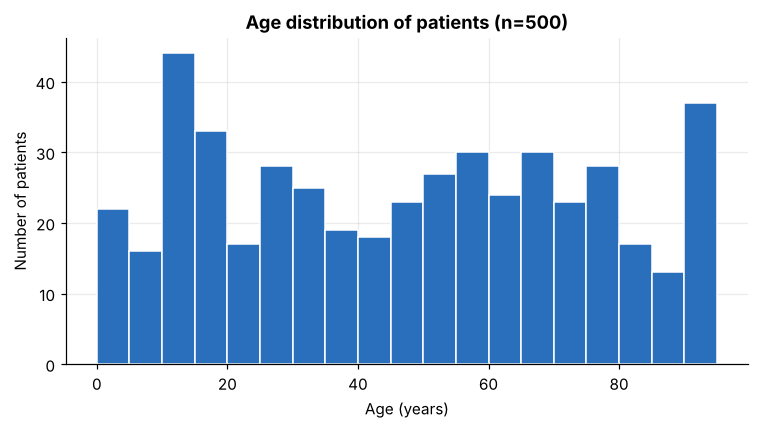

In [35]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(abt["age"], bins=range(0, 100, 5), color=BLUE, edgecolor="white")
ax.set_title("Age distribution of patients (n=500)"); ax.set_xlabel("Age (years)"); ax.set_ylabel("Number of patients")
save("01_age_distribution")

**Figure 1 - Age distribution.** Ages are spread almost evenly from 0 to 95 (median 50, mean 49.2), with no dominant age. Children (0-17) are 101 of 500 patients and 65+ patients 174: the hospital serves all life stages, so age should be used as a segmentation variable rather than dropped.

<a id="3_1_2"></a>

### 3.1.2 Gender Distribution

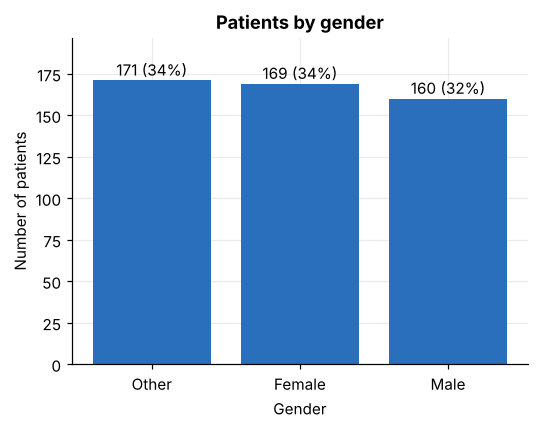

In [36]:
fig, ax = plt.subplots(figsize=(5, 4))
gc = abt["gender"].value_counts()
ax.bar(gc.index, gc.values, color=BLUE)
for i, v in enumerate(gc.values):
    ax.text(i, v + 3, f"{v} ({v/5:.0f}%)", ha="center")
ax.set_title("Patients by gender"); ax.set_xlabel("Gender"); ax.set_ylabel("Number of patients"); ax.set_ylim(0, gc.max() * 1.15)
save("02_gender")

**Figure 2 - Gender.** The three gender categories are almost balanced (Female 169, Male 160, Other 171 patients). The large 'Other' share (~1/3) is unusual for real hospital data and should be confirmed with the data owner, but it is internally consistent after cleaning.

<a id="3_1_3"></a>

### 3.1.3 Income Distribution

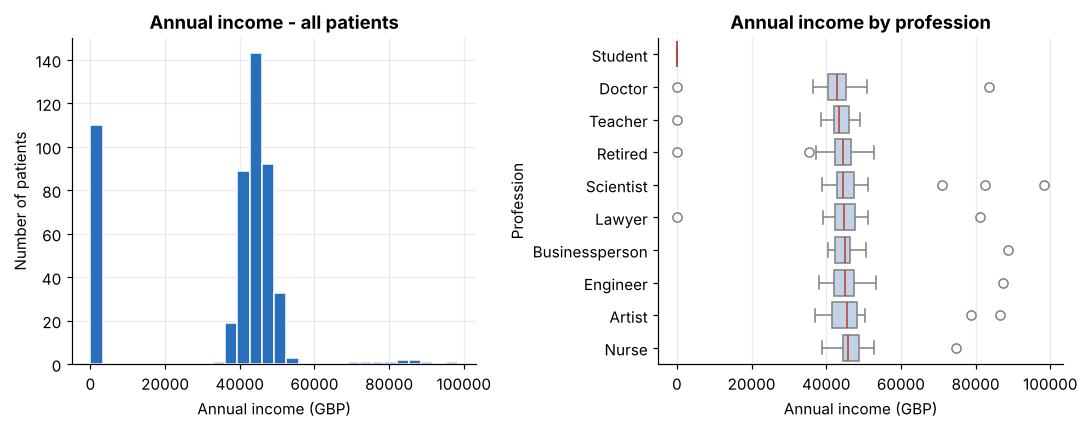

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(abt["annual_income"], bins=30, color=BLUE, edgecolor="white")
axes[0].set_title("Annual income - all patients"); axes[0].set_xlabel("Annual income (GBP)"); axes[0].set_ylabel("Number of patients")
order = abt.groupby("profession")["annual_income"].median().sort_values().index
sns.boxplot(data=abt, x="annual_income", y="profession", order=order, color="#bcd3ee", medianprops=dict(color=RED), ax=axes[1])
axes[1].set_title("Annual income by profession"); axes[1].set_xlabel("Annual income (GBP)"); axes[1].set_ylabel("Profession")
save("03_income")

**Figure 3 - Income distribution.** Median patient income is £43,458; 110 patients (22%) have zero income (children and students). Among adults, income is nearly identical across professions (~£43-46k), so profession carries little information about income, while student/non-student carries a lot.

<a id="3_2"></a>

## 3.2 Department and Service Usage

[Back to TOC](#toc)

<a id="3_2_1"></a>

### 3.2.1 Consultations by Department

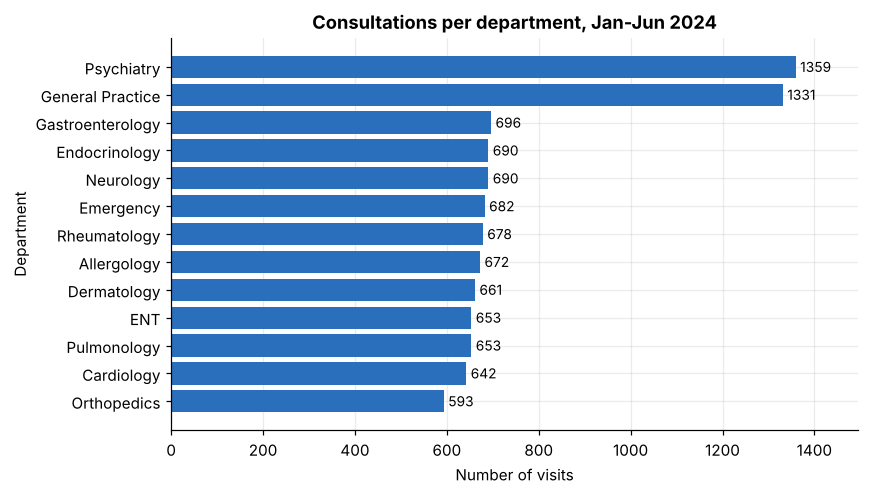

In [38]:
dv = df["Department"].astype(str).value_counts()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(dv.index[::-1], dv.values[::-1], color=BLUE)
for i, v in enumerate(dv.values[::-1]):
    ax.text(v + 10, i, str(v), va="center", fontsize=9)
ax.set_title("Consultations per department, Jan-Jun 2024"); ax.set_xlabel("Number of visits"); ax.set_ylabel("Department")
ax.set_xlim(0, dv.max() * 1.1)
save("04_visits_per_department")

**Figure 4 - Visits per department.** Psychiatry (1,359) and General Practice (1,331) are the busiest departments and together take 27% of all consultations - about twice the volume of any other department. Orthopedics is the quietest (593).

<a id="3_2_2"></a>

### 3.2.2 Consultations Over Time

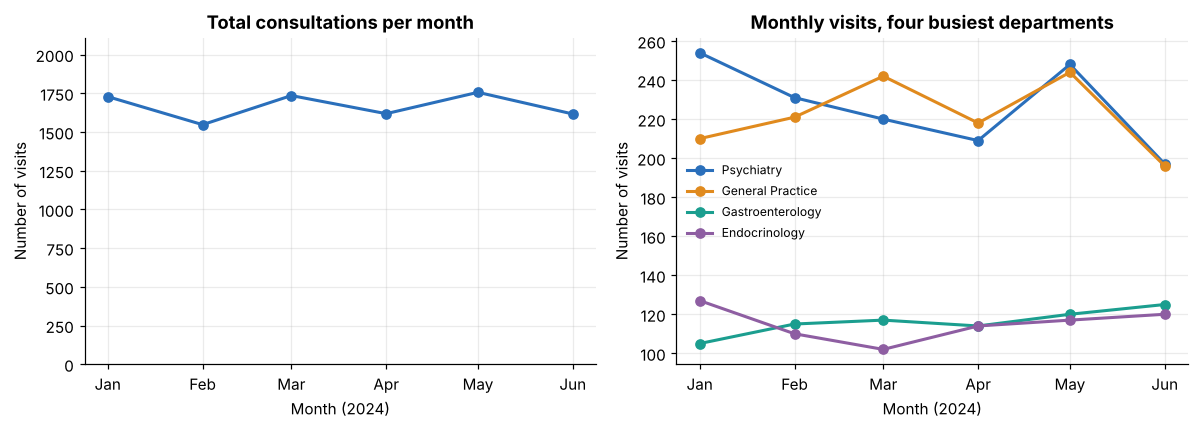

In [39]:
mt = df.groupby("Month").size()
top4 = dv.index[:4]
pm = df.groupby(["Month", "Department"], observed=True).size().unstack()
pm.columns = pm.columns.astype(str)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(mt.index, mt.values, marker="o", color=BLUE, lw=2)
axes[0].set_ylim(0, mt.max() * 1.2)
axes[0].set_title("Total consultations per month"); axes[0].set_xlabel("Month (2024)"); axes[0].set_ylabel("Number of visits")
for c, dep in zip(CAT, top4):
    axes[1].plot(pm.index, pm[dep], marker="o", lw=2, color=c, label=dep)
axes[1].set_title("Monthly visits, four busiest departments"); axes[1].set_xlabel("Month (2024)"); axes[1].set_ylabel("Number of visits")
axes[1].legend(frameon=False, fontsize=8)
for a in axes:
    a.set_xticks(mt.index); a.set_xticklabels([m.strftime("%b") for m in mt.index])
save("05_monthly_trend")

**Figure 5 - Demand over time.** Total demand is flat: 1,728 visits in January, 1,616 in June, with Feb the lowest simply because it is the shortest month (daily rate is ~53-57 visits in every month). Individual departments fluctuate (e.g. Psychiatry falls from 254 in Jan to 197 in Jun) but there is no consistent trend.

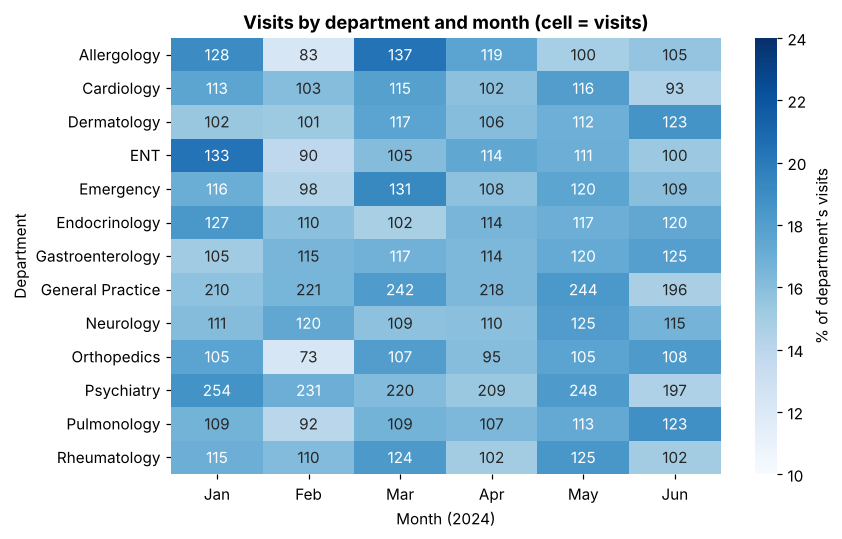

In [40]:
# heat map department x month (colour = share of the department's visits, cell = visits)
hm = pm.T
hm.columns = [m.strftime("%b") for m in hm.columns]
hm_sh = hm.div(hm.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(hm_sh, annot=hm, fmt="d", cmap="Blues", vmin=10, vmax=24, cbar_kws={"label": "% of department's visits"}, ax=ax)
ax.grid(False); ax.set_title("Visits by department and month (cell = visits)"); ax.set_xlabel("Month (2024)"); ax.set_ylabel("Department")
save("06_department_month_heatmap")

**Figure 6 - Department × month.** The heat map shows no systematic seasonality by department: counts per cell stay within ~75-255. The visible peaks (Psychiatry in Jan, General Practice in Mar/May) are modest and should be re-checked with a longer time series.

<a id="3_2_3"></a>

### 3.2.3 Department Usage by Gender or Age Group

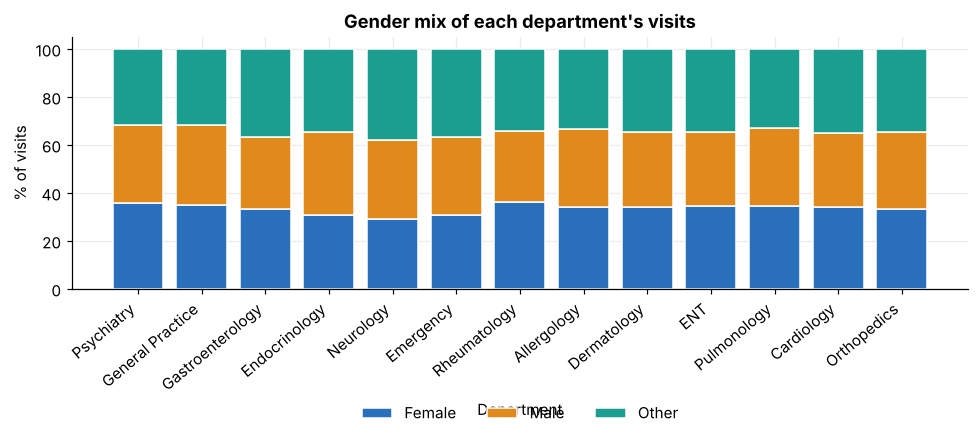

In [41]:
# department by gender (share of the department's visits)
dg = pd.crosstab(df["Department"].astype(str), df["Gender"].astype(str), normalize="index") * 100
dg = dg.loc[dv.index]
fig, ax = plt.subplots(figsize=(9, 4.6))
bottom = np.zeros(len(dg))
x = np.arange(len(dg))
for c, gname in zip([BLUE, ORANGE, TEAL], ["Female", "Male", "Other"]):
    ax.bar(x, dg[gname].values, bottom=bottom, color=c, label=gname, edgecolor="white")
    bottom += dg[gname].values
ax.set_xticks(x); ax.set_xticklabels(dg.index, rotation=40, ha="right")
ax.set_title("Gender mix of each department's visits"); ax.set_xlabel("Department"); ax.set_ylabel("% of visits")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.4))
save("07_department_by_gender")
STATS["chi2_dept_gender_p"] = perm_chi2_p(df["Department"].astype(str), df["Gender"].astype(str))

**Figure 7 - Department by gender.** Every department has a roughly one-third mix of each gender (Female share 29-36%). The differences are small and not statistically significant (permutation chi-square test, p = 0.23), so gender does not discriminate department use in this data.

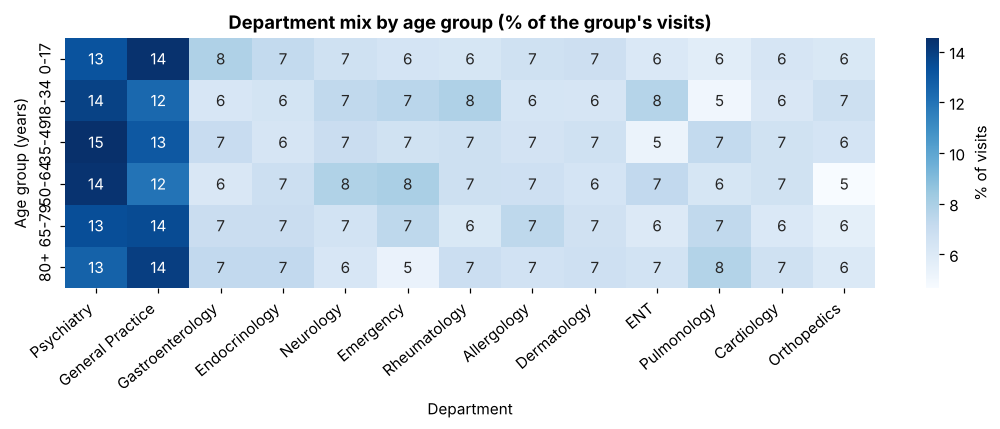

In [42]:
# department by age group (share of the age group's visits)
da = pd.crosstab(df["age_group"].astype(str), df["Department"].astype(str), normalize="index") * 100
da = da.loc[AGE_LAB, dv.index]
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(da, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of visits"}, ax=ax)
ax.grid(False); ax.set_title("Department mix by age group (% of the group's visits)"); ax.set_xlabel("Department"); ax.set_ylabel("Age group (years)")
plt.xticks(rotation=40, ha="right")
save("08_department_by_age")
STATS["chi2_dept_age_p"] = perm_chi2_p(df["age_group"].astype(str), df["Department"].astype(str))
STATS["psych_share_0_17"] = float(da.loc["0-17", "Psychiatry"]); STATS["gp_share_0_17"] = float(da.loc["0-17", "General Practice"])
STATS["dept_age_table"] = da.round(1).to_dict()

**Figure 8 - Department by age group.** Department mix is similar across age groups (permutation chi-square test, p = 0.20). Descriptive hints, to be treated as hypotheses only: Orthopedics is lowest for 50-64 (4.7% vs ~6.5% overall), Emergency is lowest for 80+ (5.3%), Pulmonology is highest for 80+ (7.7%).

<a id="3_3"></a>

## 3.3 Patient Satisfaction

[Back to TOC](#toc)

<a id="3_3_1"></a>

### 3.3.1 Satisfaction by Department

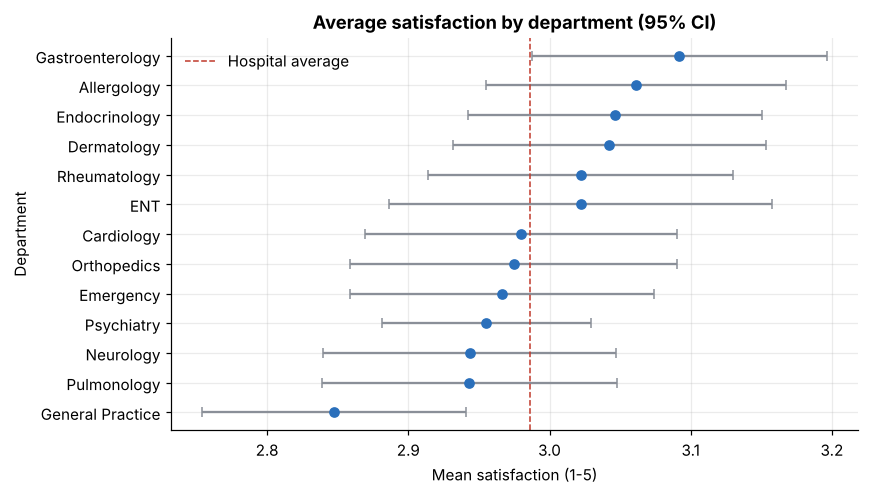

In [43]:
sat = df.dropna(subset=["Satisfaction Level"])
sd = sat.groupby("Department", observed=True)["Satisfaction Level"].agg(["mean", "std", "count"])
sd.index = sd.index.astype(str)
sd["ci"] = 1.96 * sd["std"] / np.sqrt(sd["count"])
sd = sd.sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.errorbar(sd["mean"], range(len(sd)), xerr=sd["ci"], fmt="o", color=BLUE, ecolor=GREY, capsize=3)
ax.axvline(sat["Satisfaction Level"].mean(), color=RED, ls="--", lw=1, label="Hospital average")
ax.set_yticks(range(len(sd))); ax.set_yticklabels(sd.index)
ax.set_title("Average satisfaction by department (95% CI)"); ax.set_xlabel("Mean satisfaction (1-5)"); ax.set_ylabel("Department")
ax.legend(frameon=False)
save("09_satisfaction_by_department")
STATS["anova_sat_dept_p"] = perm_anova_p(sat["Department"].astype(str), sat["Satisfaction Level"])
STATS["sat_overall"] = float(sat["Satisfaction Level"].mean())
STATS["sat_dept"] = sd[["mean", "count"]].round(3).to_dict("index")

**Figure 9 - Satisfaction by department.** Average satisfaction on the valid 1-5 scale is 2.99. General Practice is lowest (2.85) and Gastroenterology highest (3.09), but the confidence intervals overlap and the overall test is not significant (permutation ANOVA, p = 0.08). General Practice is the best candidate to monitor because it is also the second-busiest department.

<a id="3_3_2"></a>

### 3.3.2 Satisfaction by Patient Segment

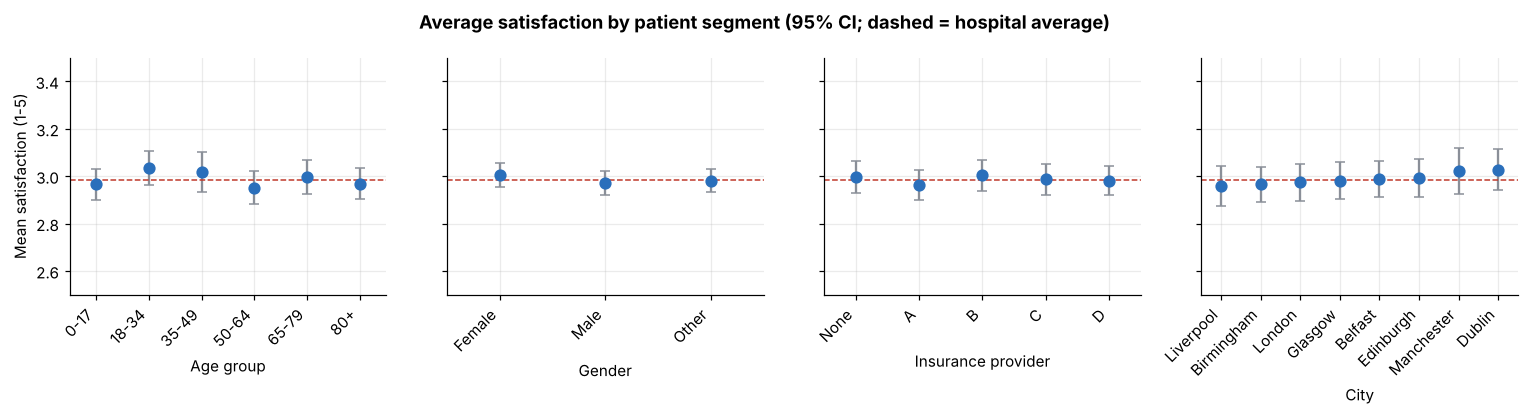

In [44]:
segs = [("age_group", "Age group", AGE_LAB), ("Gender", "Gender", ["Female", "Male", "Other"]),
        ("Insurance Provider", "Insurance provider", ["None", "Provider A", "Provider B", "Provider C", "Provider D"]),
        ("City of Residence", "City", None)]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
STATS["sat_segments"] = {}
for ax, (col, lab, order) in zip(axes, segs):
    a = sat.groupby(col, observed=True)["Satisfaction Level"].agg(["mean", "std", "count"])
    a.index = a.index.astype(str)
    a["ci"] = 1.96 * a["std"] / np.sqrt(a["count"])
    a = a.loc[order] if order is not None else a.sort_values("mean")
    ax.errorbar(range(len(a)), a["mean"], yerr=a["ci"], fmt="o", color=BLUE, ecolor=GREY, capsize=3, ms=7)
    ax.set_xticks(range(len(a)))
    ax.set_xticklabels([i.replace("Provider ", "") if col == "Insurance Provider" else i for i in a.index], rotation=45, ha="right")
    ax.set_xlabel(lab); ax.set_ylim(2.5, 3.5); ax.set_xlim(-.5, len(a) - .5)
    ax.axhline(sat["Satisfaction Level"].mean(), color=RED, ls="--", lw=1)
    STATS["sat_segments"][lab] = dict(p=perm_anova_p(sat[col].astype(str), sat["Satisfaction Level"]),
                                      means={str(k): round(float(v), 3) for k, v in a["mean"].items()})
axes[0].set_ylabel("Mean satisfaction (1-5)")
fig.suptitle("Average satisfaction by patient segment (95% CI; dashed = hospital average)", fontweight="bold")
save("10_satisfaction_by_segment")

**Figure 10 - Satisfaction by patient segment.** No patient segment stands out: age group (p = 0.54), gender (p = 0.64), insurance provider (p = 0.93) and city (p = 0.95) all sit within about ±0.1 of the hospital average of 2.99. Satisfaction is therefore not explained by the demographic variables in the ABT.

<a id="3_4"></a>

## 3.4 Additional Visualizations

[Back to TOC](#toc)

Extra charts that support the insights: rating distribution, cost split, patient activity, data-cleaning evidence and feature correlations.

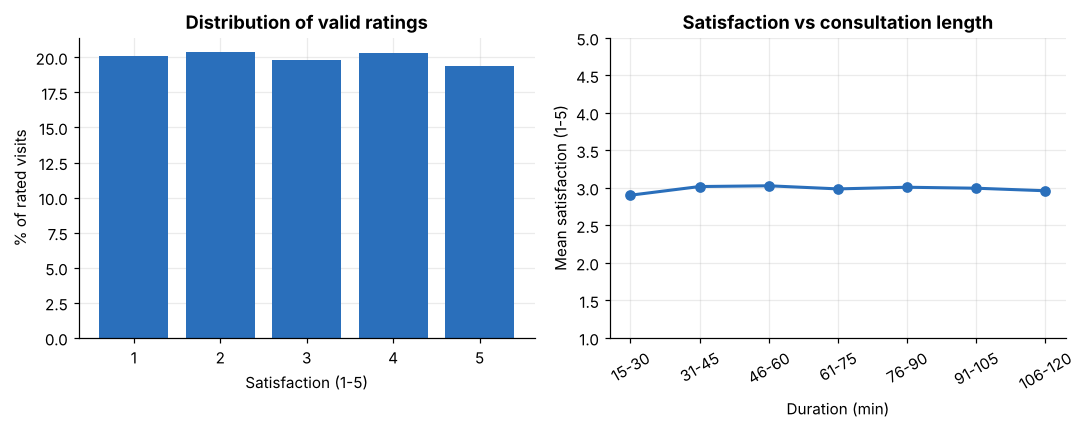

In [45]:
# satisfaction distribution + relation with consultation length
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
vc = sat["Satisfaction Level"].value_counts(normalize=True).sort_index() * 100
axes[0].bar(vc.index.astype(int), vc.values, color=BLUE)
axes[0].set_title("Distribution of valid ratings"); axes[0].set_xlabel("Satisfaction (1-5)"); axes[0].set_ylabel("% of rated visits")
dur_bins = pd.cut(sat["Consultation Duration"], [14, 30, 45, 60, 75, 90, 105, 120])
db = sat.groupby(dur_bins, observed=True)["Satisfaction Level"].mean()
axes[1].plot(range(len(db)), db.values, marker="o", color=BLUE, lw=2)
axes[1].set_xticks(range(len(db))); axes[1].set_xticklabels([f"{int(i.left)+1}-{int(i.right)}" for i in db.index], rotation=30)
axes[1].set_ylim(1, 5); axes[1].set_title("Satisfaction vs consultation length"); axes[1].set_xlabel("Duration (min)"); axes[1].set_ylabel("Mean satisfaction (1-5)")
save("11_satisfaction_distribution_duration")
STATS["corr_dur_sat"] = float(sat[["Consultation Duration", "Satisfaction Level"]].corr().iloc[0, 1])
STATS["invalid_rating_share"] = float(df["flag_rating_invalid"].mean())

**Figure 11 - Ratings and consultation length.** Ratings are spread evenly over 1-5 and are unrelated to consultation length (correlation 0.00). Note that 7.2% of visits carried an invalid rating of 6, all but 4 of them in General Practice and ENT.

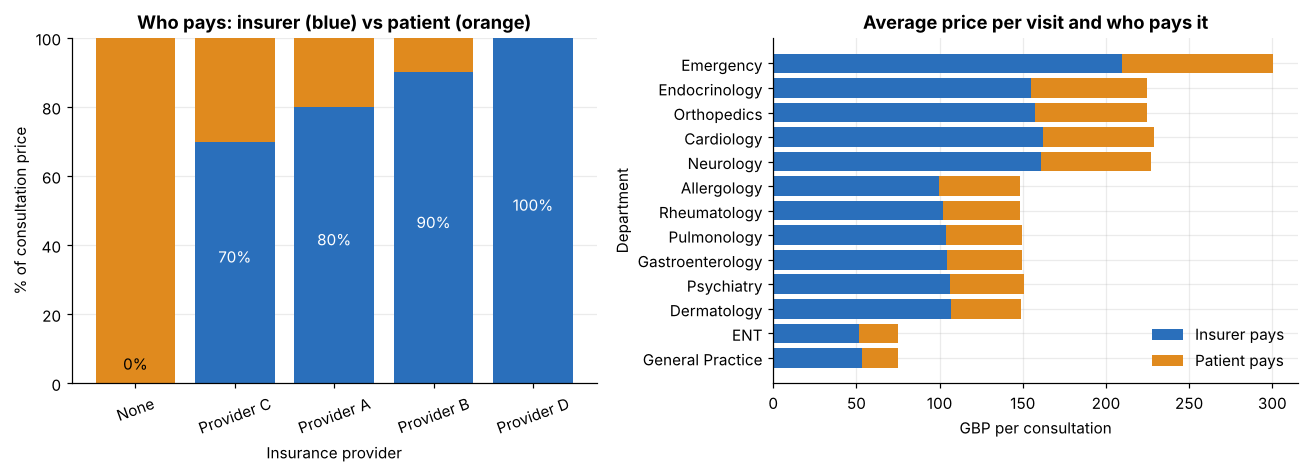

In [46]:
# financial: who pays - insurer vs patient
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
fin = df.groupby("Insurance Provider", observed=True)[["Consultation Price", "Insurance Coverage", "out_of_pocket"]].sum()
fin.index = fin.index.astype(str)
fin = fin.loc[["None", "Provider C", "Provider A", "Provider B", "Provider D"]]
cov_pct = fin["Insurance Coverage"] / fin["Consultation Price"] * 100
axes[0].bar(range(5), cov_pct.values, color=BLUE)
axes[0].bar(range(5), 100 - cov_pct.values, bottom=cov_pct.values, color=ORANGE)
axes[0].set_xticks(range(5)); axes[0].set_xticklabels(fin.index, rotation=20)
for i, v in enumerate(cov_pct.values):
    axes[0].text(i, v / 2 if v > 15 else v + 4, f"{v:.0f}%", ha="center", color="white" if v > 15 else "black")
axes[0].set_title("Who pays: insurer (blue) vs patient (orange)"); axes[0].set_xlabel("Insurance provider"); axes[0].set_ylabel("% of consultation price")
fd = df.groupby("Department", observed=True)[["Consultation Price", "Insurance Coverage", "out_of_pocket"]].sum()
fd.index = fd.index.astype(str)
fd["avg_oop"] = df.groupby("Department", observed=True)["out_of_pocket"].mean().values
fd["avg_cov"] = df.groupby("Department", observed=True)["Insurance Coverage"].mean().values
fd = fd.sort_values("avg_oop")
axes[1].barh(fd.index, fd["avg_cov"], color=BLUE, label="Insurer pays")
axes[1].barh(fd.index, fd["avg_oop"], left=fd["avg_cov"], color=ORANGE, label="Patient pays")
axes[1].set_title("Average price per visit and who pays it"); axes[1].set_xlabel("GBP per consultation"); axes[1].set_ylabel("Department")
axes[1].legend(frameon=False, loc="lower right")
save("12_financial_split")
tot_price, tot_cov = df["Consultation Price"].sum(), df["Insurance Coverage"].sum()
STATS.update(total_price=float(tot_price), total_cov=float(tot_cov), total_oop=float(tot_price - tot_cov),
             cov_share=float(tot_cov / tot_price), uninsured_patients=int((abt.has_insurance == 0).sum()),
             oop_by_ins={k: round(float(v), 2) for k, v in df.groupby("Insurance Provider", observed=True)["out_of_pocket"].mean().items()},
             avg_price_dept={k: round(float(v), 2) for k, v in df.groupby("Department", observed=True)["Consultation Price"].mean().items()},
             avg_oop_dept={k: round(float(v), 2) for k, v in df.groupby("Department", observed=True)["out_of_pocket"].mean().items()},
             avg_price_visit=float(df["Consultation Price"].mean()), avg_oop_visit=float(df["out_of_pocket"].mean()),
             oop_share_of_oop_by_uninsured=float(df.loc[df["Insurance Provider"].astype(str) == "None", "out_of_pocket"].sum() / (tot_price - tot_cov)))

**Figure 12 - Insurance coverage and out-of-pocket cost.** Insurers cover 69.9% of the £1,651,138 billed (patients pay £496,679, 30.1%). Coverage follows a fixed rule per provider (C 70%, A 80%, B 90%, D 100%, none 0%). The 90 uninsured patients (18%) pay 60% of all out-of-pocket money (≈£164 per visit). Emergency (≈£300/visit) is the costliest department; ENT and General Practice (≈£75) the cheapest.

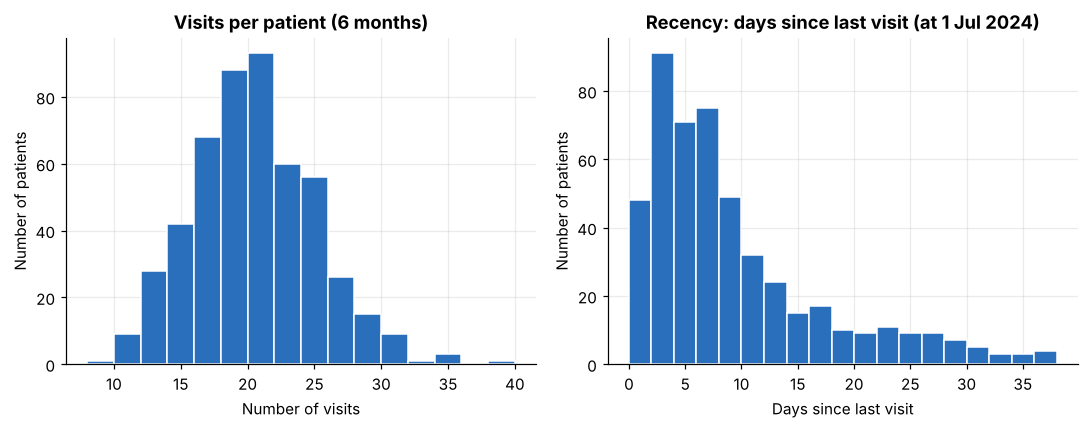

In [47]:
# visits per patient + recency
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(abt["n_visits"], bins=range(8, 42, 2), color=BLUE, edgecolor="white")
axes[0].set_title("Visits per patient (6 months)"); axes[0].set_xlabel("Number of visits"); axes[0].set_ylabel("Number of patients")
axes[1].hist(abt["days_since_last_visit"], bins=range(0, 40, 2), color=BLUE, edgecolor="white")
axes[1].set_title("Recency: days since last visit (at 1 Jul 2024)"); axes[1].set_xlabel("Days since last visit"); axes[1].set_ylabel("Number of patients")
save("13_visits_recency")

**Figure 13 - Visits per patient and recency.** Patients visit 20 times on average in six months (range 9-39) and the median patient was last seen only 6.5 days before the reference date (max 53). All 500 patients are active, so recency cannot identify churn in this window.

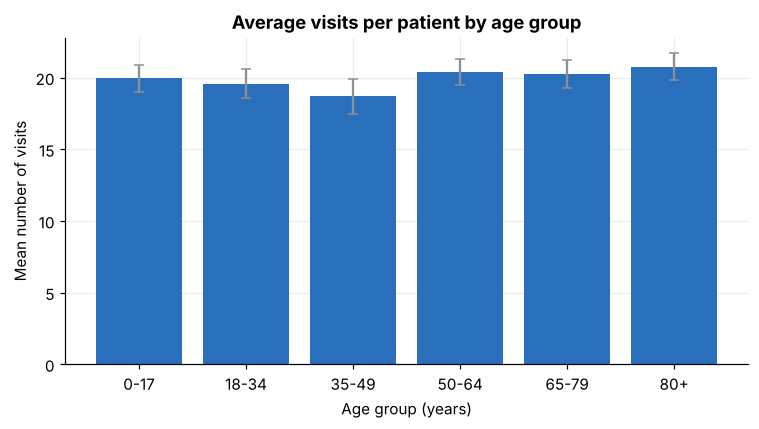

ANOVA (permutation) p-value, visits by age group: 0.13


In [48]:
# visits per patient by age group
fig, ax = plt.subplots(figsize=(7, 4))
vp = abt.groupby("age_group")["n_visits"].agg(["mean", "std", "count"]).loc[AGE_LAB]
ax.bar(range(6), vp["mean"], yerr=1.96 * vp["std"] / np.sqrt(vp["count"]), color=BLUE, capsize=3, ecolor=GREY)
ax.set_xticks(range(6)); ax.set_xticklabels(AGE_LAB); ax.set_title("Average visits per patient by age group")
ax.set_xlabel("Age group (years)"); ax.set_ylabel("Mean number of visits")
save("14_visits_by_age_group")
STATS["visits_by_age"] = vp["mean"].round(2).to_dict()
STATS["anova_visits_age_p"] = perm_anova_p(abt["age_group"], abt["n_visits"])
print(f"ANOVA (permutation) p-value, visits by age group: {STATS['anova_visits_age_p']:.2f}")

**Figure 14 - Visits by age group.** The number of visits per patient does not depend on age (all groups 18.7-20.7 visits; permutation ANOVA p = 0.13).

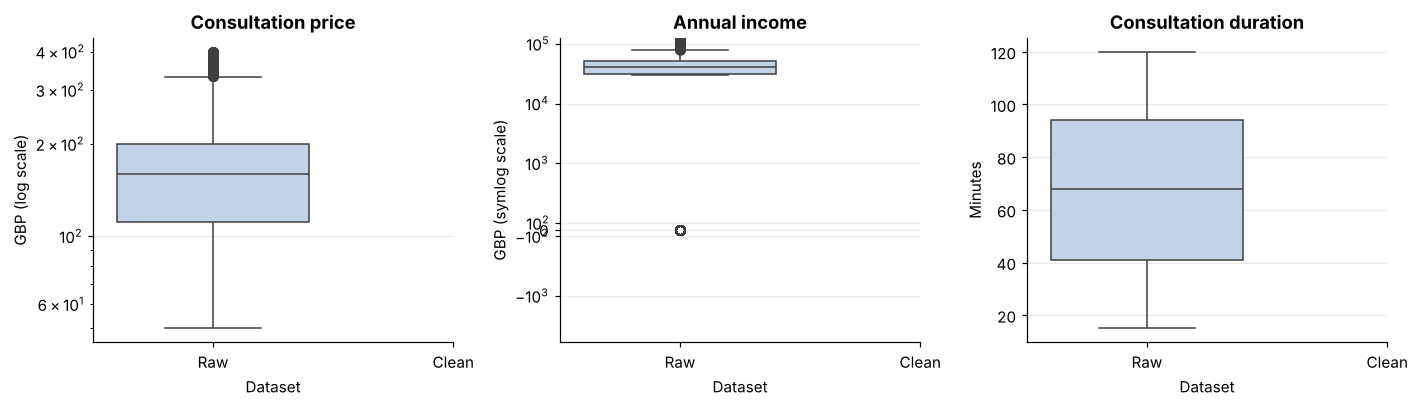

In [49]:
# data-cleaning evidence: raw vs clean price / income / duration
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
pairs = [("Consultation Price", "Consultation price", "GBP (log scale)", "log"),
         ("Approximate Annual Income", "Annual income", "GBP (symlog scale)", "symlog"),
         ("Consultation Duration", "Consultation duration", "Minutes", None)]
for ax, (c, title, ylab, scale) in zip(axes, pairs):
    sns.boxplot(data=[data[c].dropna().astype(float), df[c].dropna().astype(float)], ax=ax, color="#bcd3ee")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Raw", "Clean"])
    if scale == "log":
        ax.set_yscale("log")
    elif scale == "symlog":
        ax.set_yscale("symlog", linthresh=1000)
    ax.set_title(title); ax.set_ylabel(ylab); ax.set_xlabel("Dataset")
save("15_cleaning_before_after")

**Figure 15 - Cleaning: before vs after.** Before/after view of the three numeric outliers fixed in cleaning: price (×100 errors up to £40,000), income (×10/×100 errors up to £12M) and duration (up to 600 min). After cleaning, all values lie in plausible ranges (price £50-400, duration 15-120 min).

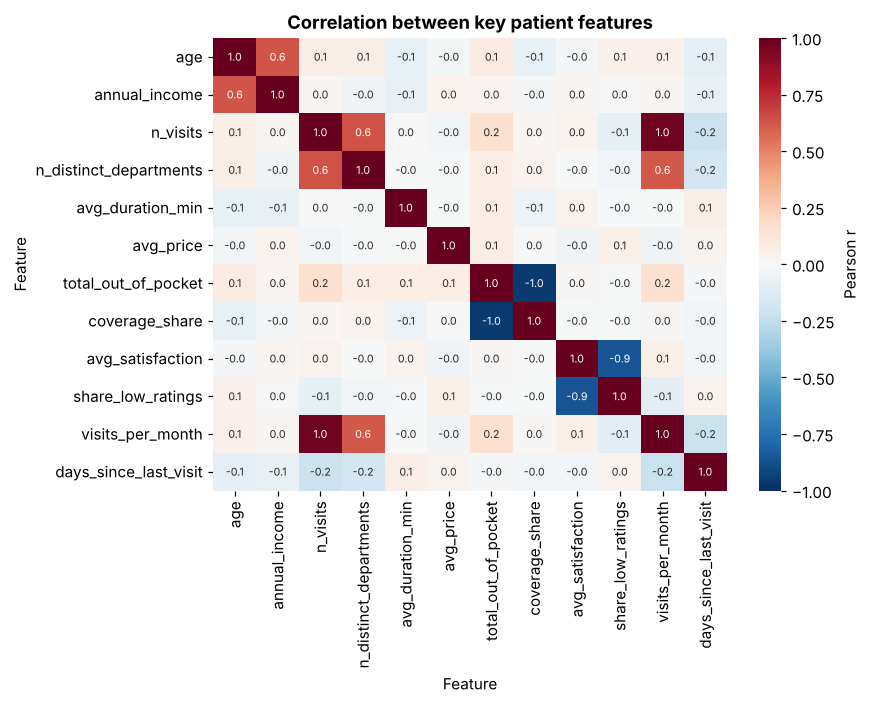

In [50]:
# correlation of key ABT features
cols = ["age", "annual_income", "n_visits", "n_distinct_departments", "avg_duration_min", "avg_price",
        "total_out_of_pocket", "coverage_share", "avg_satisfaction", "share_low_ratings", "visits_per_month", "days_since_last_visit"]
cm = abt[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".1f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7}, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.grid(False); ax.set_title("Correlation between key patient features"); ax.set_xlabel("Feature"); ax.set_ylabel("Feature")
save("16_correlation")
STATS["corr_pairs"] = {f"{a}|{b}": round(float(cm.loc[a, b]), 2) for a in cols for b in cols if a < b and abs(cm.loc[a, b]) > .3}

**Figure 16 - Correlation of key ABT features.** Strongest relations are mechanical: visits and visits per month (0.97), coverage share vs out-of-pocket (-0.95), average satisfaction vs share of low ratings (-0.86). Age-income (0.63) reflects zero income for children/students. Most behavioural and satisfaction features are nearly uncorrelated, so a predictive model should not expect strong signals.

<a id="3_5"></a>

## 3.5 Management Questions and Key Insights

[Back to TOC](#toc)

In [51]:
# Key figures behind the answers below (all computed from the cleaned data)
days = mt.index.days_in_month
print("Q1  Visits per department (share of all visits):")
display(pd.DataFrame({"visits": dv, "share_%": (dv / dv.sum() * 100).round(1)}).T)
print("    Visits per month and per day:")
display(pd.DataFrame({"visits": mt.values, "per_day": (mt.values / days).round(1)}, index=[m.strftime("%b") for m in mt.index]).T)
chg = ((pm.loc[pm.index.min()] - pm.loc[pm.index.max()]) * -1)
print("    Change in visits, Jan -> Jun, by department:")
display(chg.sort_values().to_frame("jun_minus_jan").T)

print("Q2  Most used department by age group and gender (share of that group's visits):")
top_age = pd.DataFrame({"top_department": da.idxmax(axis=1), "share_%": da.max(axis=1).round(1)})
dgx = pd.crosstab(df["Gender"].astype(str), df["Department"].astype(str), normalize="index") * 100   # share of each gender's visits
top_gen = pd.DataFrame({"top_department": dgx.idxmax(axis=1), "share_%": dgx.max(axis=1).round(1)})
display(top_age.T)
print("    ... and by gender:")
display(top_gen.T)
print(f"    chi-square p-values - department vs age group: {STATS['chi2_dept_age_p']:.2f} | vs gender: {STATS['chi2_dept_gender_p']:.2f}")

print("Q3  Satisfaction (valid ratings), lowest departments and overall:")
display(sd[["mean", "count"]].round(2).head(4).T)
print(f"    overall {STATS['sat_overall']:.2f} | ANOVA by department p = {STATS['anova_sat_dept_p']:.2f}")
print("    segment tests (p-values):", {k: round(v["p"], 2) for k, v in STATS["sat_segments"].items()})

print("Q4  Who pays the consultation price:")
print(f"    billed £{STATS['total_price']:,.0f} | insurers £{STATS['total_cov']:,.0f} ({STATS['cov_share']:.1%}) | "
      f"patients £{STATS['total_oop']:,.0f} ({1 - STATS['cov_share']:.1%})")
print(f"    uninsured patients: {STATS['uninsured_patients']} ({STATS['uninsured_patients']/5:.0f}%), they pay "
      f"{STATS['oop_share_of_oop_by_uninsured']:.0%} of all out-of-pocket money")
print(f"    average price per visit £{STATS['avg_price_visit']:.0f}, average out-of-pocket £{STATS['avg_oop_visit']:.0f}")

Q1  Visits per department (share of all visits):


Department,Psychiatry,General Practice,Gastroenterology,Endocrinology,Neurology,Emergency,Rheumatology,Allergology,Dermatology,ENT,Pulmonology,Cardiology,Orthopedics
visits,1359.0,1331.0,696.0,690.0,690.0,682.0,678.0,672.0,661.0,653.0,653.0,642.0,593.0
share_%,13.6,13.3,7.0,6.9,6.9,6.8,6.8,6.7,6.6,6.5,6.5,6.4,5.9


    Visits per month and per day:


,Jan,Feb,Mar,Apr,May,Jun
visits,1728.0,1547.0,1735.0,1618.0,1756.0,1616.0
per_day,55.7,53.3,56.0,53.9,56.6,53.9


    Change in visits, Jan -> Jun, by department:


Department,Psychiatry,ENT,Allergology,Cardiology,General Practice,Rheumatology,Endocrinology,Emergency,Orthopedics,Neurology,Pulmonology,Gastroenterology,Dermatology
jun_minus_jan,-57,-33,-23,-20,-14,-13,-7,-7,3,4,14,20,21


... (3 outputs left out)

Gender,Female,Male,Other
top_department,Psychiatry,Psychiatry,Psychiatry
share_%,14.4,13.8,12.6


    chi-square p-values - department vs age group: 0.20 | vs gender: 0.23
Q3  Satisfaction (valid ratings), lowest departments and overall:


Department,General Practice,Pulmonology,Neurology,Psychiatry
mean,2.85,2.94,2.94,2.96
count,859.00,652.00,690.00,1357.00


    overall 2.99 | ANOVA by department p = 0.08
    segment tests (p-values): {'Age group': 0.54, 'Gender': 0.64, 'Insurance provider': 0.93, 'City': 0.95}
Q4  Who pays the consultation price:
    billed £1,651,138 | insurers £1,154,460 (69.9%) | patients £496,679 (30.1%)
    uninsured patients: 90 (18%), they pay 60% of all out-of-pocket money
    average price per visit £165, average out-of-pocket £50


**Answers to management's questions**

1. **Busiest departments and demand from January to June.** Psychiatry (1,359 visits) and General Practice (1,331) are the busiest, together 27% of all consultations and about twice any other department; Orthopedics is the quietest (593). Total demand is flat over the six months (1,728 visits in January, 1,616 in June; ~53-57 visits per day in every month). Departments fluctuate month to month (Psychiatry 254 → 197) but there is no consistent trend or seasonality.
2. **Which patient groups use which departments.** Department mix is very similar across age groups (p = 0.20) and genders (p = 0.23), so no group is tied to a department. The most-used department is General Practice for children (0-17) and for 65+, and Psychiatry for ages 18-64, but always with only ~14% of the group's visits, a negligible lead. Only weak hints exist (Orthopedics lowest for 50-64, Emergency lowest and Pulmonology highest for 80+) and should be treated as hypotheses.
3. **Lowest satisfaction.** Average satisfaction is 2.99/5. General Practice is lowest (2.85) and Gastroenterology highest (3.09), but the differences are not significant (p = 0.08). No patient segment (age, gender, insurer, city) differs from the average either, so satisfaction is not explained by the demographics in the ABT. General Practice deserves monitoring because it is both the lowest-rated and the second-busiest department.
4. **Insurance vs out-of-pocket.** Insurers cover 69.9% of the £1.65M billed; patients pay £496,679 (30.1%). Coverage is a fixed rate per provider (C 70%, A 80%, B 90%, D 100%, none 0%). The 90 uninsured patients (18%) pay about 60% of all out-of-pocket money (≈£164 per visit).

**Suggestions for the next analytics team**

- **Sensible targets:** `avg_satisfaction` / `share_low_ratings` (experience), `n_visits` / `visits_per_month` (utilisation), `total_out_of_pocket` or `oop_to_income_pct` (financial burden) and `top_department` (service demand). Expect weak signals: most behavioural and satisfaction features are almost uncorrelated.
- **Segmentation ideas:** cluster on age group, income, insurance status and utilisation (`n_visits`, `n_distinct_departments`, `share_emergency`); treat uninsured patients as a distinct group because of their financial exposure.
- **Caveats:** all patients were active in the window, so recency cannot define churn; the `Other` gender share (~1/3) should be confirmed; the rating-6 code is concentrated in two departments; four patients have a profession that does not fit their age (`profession_age_odd`); and visits flagged in `flag_same_day_same_dept` may need review. Use the `dq_*` columns to test how sensitive any result is to repaired data.

In [52]:
# extra numbers kept in STATS for the report and the slides
STATS["gender_counts"] = abt["gender"].value_counts().to_dict()
STATS["age_stats"] = abt["age"].describe().round(1).to_dict()
STATS["age_group_counts"] = abt["age_group"].value_counts().reindex(AGE_LAB).to_dict()
STATS["income_stats"] = abt["annual_income"].describe().round(0).to_dict()
STATS["income_zero_patients"] = int((abt["annual_income"] == 0).sum())
STATS["dept_visits"] = dv.to_dict()
STATS["monthly_visits"] = {k.strftime("%b"): int(v) for k, v in mt.items()}
STATS["dept_month"] = {d_: {m.strftime("%b"): int(v) for m, v in pm[d_].items()} for d_ in pm.columns}
STATS["profession_counts"] = abt["profession"].value_counts().to_dict()
STATS["insurance_counts"] = abt["insurance_provider"].value_counts().to_dict()
STATS["top_dept_counts"] = abt["top_department"].value_counts().to_dict()
STATS["abt_visits"] = abt["n_visits"].describe().round(2).to_dict()
STATS["abt_distinct_dept"] = abt["n_distinct_departments"].describe().round(2).to_dict()
STATS["abt_avg_sat"] = abt["avg_satisfaction"].describe().round(2).to_dict()
STATS["abt_low_share"] = abt["share_low_ratings"].describe().round(3).to_dict()
STATS["abt_days_last"] = abt["days_since_last_visit"].describe().round(1).to_dict()
STATS["dept_gender"] = dg.round(1).to_dict()
STATS["dept_avg_duration"] = df.groupby("Department", observed=True)["Consultation Duration"].mean().round(1).to_dict()
STATS["profession_sat"] = sat.assign(prof=sat["Patient ID"].map(abt.set_index("patient_id")["profession"])).groupby("prof")["Satisfaction Level"].mean().round(3).to_dict()
STATS["cleaning_log"] = LOG
print("Done. ABT:", abt.shape, "| clean visits:", len(df))

Done. ABT: (500, 67) | clean visits: 10000


## Summary
See the accompanying report and slides (PDF) for the full discussion, the data dictionary and recommendations for the next analytics team.